# FCA-PAD v5: benchmark detectors on realistic worlds, with and without the financial layer
Does a detector that finds anomalies well also find the anomalies that **cost money**, when most
anomalies are harmless? And does adding the FCA-PAD financial layer fix that, for any detector?

Runs **after the v2 notebook** for the same log (it reuses v2's saved models, split and rules; nothing of
v2 is changed). Builds the same realistic worlds as v4 (same seeds), trains **GAMA** and **DAE** on the
same clean training cases and inputs as our **LSTM**, and compares all of them alone and with the layer.

**How to run:** GPU runtime recommended (GAMA trains much faster). Set `LOG_NAME` in cell 0.3,
then Runtime → Run all. Repeat per log. Part E combines every log that has been run.
Outputs: `<log folder>/19_v5_detectors/` and `MyDrive/FCA_PAD_v2/19_v5_summary/`.
RAM: GAMA and DAE run in separate processes; if a run is killed for memory, set `V5_SEEDS` to
fewer seeds (e.g. `os.environ["V5_SEEDS"] = "404,505"` at the top of cell 0.3).


## Part A · v2 core (loads saved artefacts; trains nothing)


In [ ]:
# 0.1 Environment detection + package install
import importlib.util, os, subprocess, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
for pkg in ("pm4py", "pyarrow"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
# PuLP 4.0 (Oct 2026) removed names pm4py imports at start-up (LpStatus) -> pin PuLP < 4.
from importlib.metadata import version as _ver, PackageNotFoundError
try:
    _pulp_major = int(_ver("pulp").split(".")[0])
except PackageNotFoundError:
    _pulp_major = None
if _pulp_major is None or _pulp_major >= 4:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pulp<4"], check=True)
    if "pulp" in sys.modules or "pm4py" in sys.modules:
        raise SystemExit("PuLP was downgraded. Restart the session (Runtime > Restart session), then run again.")
print("Running in Colab:", IN_COLAB)


Running in Colab: True


In [ ]:
# 0.2 Safe Google Drive mount
# Removes /content/drive ONLY when it is a leftover local folder, never when
# it is the mounted Drive (deleting a mounted Drive deletes your real files).
if IN_COLAB:
    import shutil
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        if os.path.exists("/content/drive"):
            shutil.rmtree("/content/drive")
        drive.mount("/content/drive")
    else:
        print("Drive already mounted.")


Drive already mounted.


In [ ]:
# 0.3 CONFIGURATION — the only cell you should need to edit
import json, datetime, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ---- where everything lives (NEW folder; v1 folders untouched) ----------
LOG_NAME = os.environ.get("FCA_LOG", "BPIC20_D")   # BPIC20_D | BPIC20_I | BPIC20_PR | BPIC20_R

LOGS = {   # benchmark name -> file in github.com/guanwei49/BPAD/generator/real-life_Logs, amount field
    "BPIC20_D":  {"xes": "BPIC20_DomesticDeclarations.xes",      "amount": "case:Amount",
                  "local_xes": "DomesticDeclarations.xes", "multi_batch_hrs": 180},
    "BPIC20_I":  {"xes": "BPIC20_InternationalDeclarations.xes", "amount": "case:Amount"},
    "BPIC20_PR": {"xes": "BPIC20_PrepaidTravelCost.xes",         "amount": "case:RequestedAmount"},
    "BPIC20_R":  {"xes": "BPIC20_RequestForPayment.xes",         "amount": "case:RequestedAmount"},
}
assert LOG_NAME in LOGS, f"LOG_NAME must be one of {list(LOGS)}"
LOG_CFG = LOGS[LOG_NAME]
BASE_ROOT = ("/content/drive/MyDrive/FCA_PAD_v2" if IN_COLAB else os.path.abspath("FCA_PAD_v2"))
BASE_ROOT = os.environ.get("FCA_ROOT", BASE_ROOT)
ROOT = BASE_ROOT if LOG_NAME == "BPIC20_D" else f"{BASE_ROOT}/{LOG_NAME}"
XES_FILE = LOG_CFG.get("local_xes", LOG_CFG["xes"])
XES_URL = ("https://raw.githubusercontent.com/guanwei49/BPAD/master/generator/real-life_Logs/"
           + LOG_CFG["xes"])

# ---- dataset mapping (shared by all BPIC20 logs) --------------------------
CASE_COL, ACTIVITY_COL, TIME_COL = "case:concept:name", "concept:name", "time:timestamp"
ROLE_COL, RESOURCE_COL = "org:role", "org:resource"
AMOUNT_COL = LOG_CFG["amount"]
ACT_REQUEST = "Request Payment"
ACT_PAYMENT = "Payment Handled"
SUBMIT_TOKEN = "SUBMITTED by EMPLOYEE"   # any submission activity (declaration, permit, request)
REJECT_TOKEN = "REJECTED"                # any rejection activity
APPROVE_TOKEN = "APPROVED"               # any approval activity (incl. FINAL_APPROVED)

# ---- data-derived constants (None = derive from the log) ----------------
BATCH_WEEKDAYS = None   # BPIC20_D derives to [0, 3] = Monday, Thursday
BATCH_HOUR = None       # BPIC20_D derives to 15
MULTI_BATCH_HRS = LOG_CFG.get("multi_batch_hrs")   # D: 180 (v1 value); others: derived
REPEAT_WINDOW_D = 7     # cross-case amount proximity window (days)
RARE_AMOUNT_MAX = 3     # amount in <= N cases = rare
HEAVY_REWORK_LOOPS = 2

# ---- experiment settings ----------------------------------------------
RANDOM_SEED = 42
SPLIT = (0.60, 0.20, 0.20)              # train / val / test, by case
BUCKET_EDGES = (3, 5)                   # prefix buckets 1-3 | 4-5 | 6+
MIN_PREFIXES_PER_BUCKET = 2000
INJ_RATE = 0.05
INJ_TYPES = ["A1", "A2", "A4", "A5"]    # A3 omitted (no adjusted-amount field)
ALERT_FPR = 0.01                        # early-warning threshold on natural val prefixes
BOOTSTRAP_B = 200                       # bootstrap resamples for fusion selection
SEEDS_ROBUSTNESS = [42, 7, 123]
RUN_SEED_ROBUSTNESS = True
RUN_REGIME2 = True
NE_MAXLEN = 32                          # natural max 24; injection adds <= 2
AE_MAXLEN = 32
NE_EPOCHS, AE_EPOCHS = 60, 30
FORCE_RECOMPUTE = False   # True: ignore cached stage outputs
FORCE_REFREEZE = False    # True: overwrite FROZEN artefacts — leave False
if os.environ.get("FCA_SKIP_ROBUSTNESS"):   # skip section 10 (seeds + Regime 2) to save time
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False
if os.environ.get("FCA_FAST"):          # quick code-path test only; never for results
    NE_EPOCHS = AE_EPOCHS = 2
    RUN_SEED_ROBUSTNESS = RUN_REGIME2 = False

# ---- folders -------------------------------------------------------------
RAW_DIR, PROCESSED_DIR = f"{ROOT}/01_raw", f"{ROOT}/02_processed"
FEATURE_DIR, MODEL_DIR = f"{ROOT}/03_features", f"{ROOT}/04_models"
RESULT_DIR, FIGURE_DIR = f"{ROOT}/05_results", f"{ROOT}/06_figures"
FROZEN_DIR = f"{ROOT}/00_frozen"
for d in [RAW_DIR, PROCESSED_DIR, FEATURE_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR, FROZEN_DIR]:
    os.makedirs(d, exist_ok=True)

np.random.seed(RANDOM_SEED)

def cached(path):
    return os.path.exists(path) and not FORCE_RECOMPUTE

def write_frozen(path, writer):
    """Write a frozen artefact once. Returns True if written now."""
    if os.path.exists(path) and not FORCE_REFREEZE:
        print(f"FROZEN (kept existing): {os.path.basename(path)}")
        return False
    writer(path)
    print(f"FROZEN (written now):  {os.path.basename(path)}")
    return True

E1, E2 = BUCKET_EDGES
BUCKETS = [f"1-{E1}", f"{E1+1}-{E2}", f"{E2+1}+"]
def bucket_of(k):
    return BUCKETS[0] if k <= E1 else (BUCKETS[1] if k <= E2 else BUCKETS[2])

def midpoint_rank(values, ref):
    """Percentile of values within sorted ref; ties get the tie-block midpoint."""
    ref = np.asarray(ref)
    if len(ref) == 0:
        return np.zeros(len(values))
    lo = np.searchsorted(ref, values, side="left")
    hi = np.searchsorted(ref, values, side="right")
    return np.clip((lo + hi) / 2 / len(ref), 0, 1)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURE_DIR}/{name}.png", dpi=130)
    plt.show()
    plt.close()

env = {"python": sys.version.split()[0], "platform": platform.platform(),
       "pandas": pd.__version__, "numpy": np.__version__,
       "run_started": datetime.datetime.now().isoformat(timespec="seconds"),
       "root": ROOT, "log": LOG_NAME}
json.dump(env, open(f"{RESULT_DIR}/00_environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))


{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "run_started": "2026-10-13T05:19:07",
  "root": "/content/drive/MyDrive/FCA_PAD_v2",
  "log": "BPIC20_D"
}


In [ ]:
# A.0 v5 guard: side outputs of the v2 core go to a scratch folder; nothing may be trained
V2_RESULT_DIR = RESULT_DIR
V5_DIR = f"{ROOT}/19_v5_detectors"
V4_DIR = V5_DIR
RESULT_DIR, FIGURE_DIR = f"{V5_DIR}/_v2_core_outputs", f"{V5_DIR}/_v2_core_figures"
for d in (RESULT_DIR, FIGURE_DIR):
    os.makedirs(d, exist_ok=True)
FORCE_RECOMPUTE = FORCE_REFREEZE = False
_needed = [f"{PROCESSED_DIR}/events_sorted.parquet", f"{FEATURE_DIR}/prefix_features.parquet",
           f"{FEATURE_DIR}/natural_scores.parquet", f"{MODEL_DIR}/next_event.keras", f"{MODEL_DIR}/ae.keras",
           f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/calibration_refs.joblib", f"{MODEL_DIR}/ne_meta.joblib",
           f"{FROZEN_DIR}/case_split.csv", f"{FROZEN_DIR}/rule_registry_v1.json",
           f"{FROZEN_DIR}/ground_truth_sealed.csv", f"{V2_RESULT_DIR}/07_fusion_selected.json"]
_missing = [p for p in _needed if not os.path.exists(p)]
if _missing:
    raise SystemExit("Run the v2 notebook for " + LOG_NAME + " first. Missing:\n  " + "\n  ".join(_missing))
print("v2 artefacts found for", LOG_NAME, "| v5 outputs ->", V5_DIR)


v2 artefacts found for BPIC20_D | v5 outputs -> /content/drive/MyDrive/FCA_PAD_v2/19_v5_detectors


In [ ]:
# 1.1 Load XES (or cached parquet), schema audit, quality checks, freeze
EVENTS_PATH = f"{PROCESSED_DIR}/events_sorted.parquet"
if cached(EVENTS_PATH):
    events = pd.read_parquet(EVENTS_PATH)
    print("Loaded cached events:", events.shape)
else:
    import pm4py
    xes_path = f"{RAW_DIR}/{XES_FILE}"
    if not os.path.exists(xes_path):
        import urllib.request, time as _t
        print(f"{XES_FILE} not in {RAW_DIR} - downloading from the benchmark repository ...")
        tmp = xes_path + ".part"
        for attempt in range(1, 4):              # download to .part, verify, then move into place
            try:
                with urllib.request.urlopen(XES_URL, timeout=120) as r:
                    expected = int(r.headers.get("Content-Length", 0))
                    with open(tmp, "wb") as fh:
                        while True:
                            chunk = r.read(1 << 20)
                            if not chunk:
                                break
                            fh.write(chunk)
                got = os.path.getsize(tmp)
                if expected and got != expected:
                    raise IOError(f"incomplete download: {got} of {expected} bytes")
                os.replace(tmp, xes_path)
                break
            except Exception as e:
                if os.path.exists(tmp):
                    os.remove(tmp)
                print(f"  attempt {attempt} failed: {e}")
                if attempt == 3:
                    raise RuntimeError(f"Download failed - upload {LOG_CFG['xes']} into {RAW_DIR} "
                                       f"and re-run this cell.") from e
                _t.sleep(5 * attempt)
        print("Downloaded", round(os.path.getsize(xes_path) / 1e6, 1), "MB")
    raw_df = pm4py.convert_to_dataframe(pm4py.read_xes(xes_path)).copy()
    print("Raw dataframe:", raw_df.shape)

    schema = pd.DataFrame([{
        "column": c, "dtype": str(raw_df[c].dtype),
        "n_unique": int(raw_df[c].nunique(dropna=True)),
        "missing_pct": round(float(raw_df[c].isna().mean() * 100), 3),
        "example": str(raw_df[c].dropna().iloc[0]) if raw_df[c].notna().any() else ""}
        for c in raw_df.columns])
    schema.to_csv(f"{RESULT_DIR}/01_raw_schema.csv", index=False)
    print(schema.to_string(index=False))

    raw_df[TIME_COL] = pd.to_datetime(raw_df[TIME_COL], utc=True, errors="coerce")
    if AMOUNT_COL in raw_df:
        raw_df[AMOUNT_COL] = pd.to_numeric(raw_df[AMOUNT_COL], errors="coerce")
    quality = {
        "missing_case_id": int(raw_df[CASE_COL].isna().sum()),
        "missing_activity": int(raw_df[ACTIVITY_COL].isna().sum()),
        "missing_or_bad_timestamp": int(raw_df[TIME_COL].isna().sum()),
        "exact_duplicate_rows": int(raw_df.astype(str).duplicated().sum()),
        "missing_amount": int(raw_df[AMOUNT_COL].isna().sum()) if AMOUNT_COL in raw_df else None,
    }
    print("Quality:", quality)
    # Rule: never delete records for looking unusual — only structurally invalid ones.
    bad = raw_df[CASE_COL].isna() | raw_df[ACTIVITY_COL].isna() | raw_df[TIME_COL].isna()
    print("Structurally invalid rows removed:", int(bad.sum()))
    raw_df = raw_df[~bad].copy()

    keep = {CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, RESOURCE_COL, AMOUNT_COL}
    const_cols = [c for c in raw_df.columns
                  if c not in keep and raw_df[c].nunique(dropna=False) <= 1]
    print("Constant columns dropped:", const_cols)
    raw_df = raw_df.drop(columns=const_cols)

    raw_df[CASE_COL] = raw_df[CASE_COL].astype(str)
    raw_df["_orig_order"] = np.arange(len(raw_df))
    events = (raw_df.sort_values([CASE_COL, TIME_COL, "_orig_order"])
              .drop(columns="_orig_order").reset_index(drop=True))
    events["event_idx"] = events.groupby(CASE_COL).cumcount() + 1
    for c in events.columns:                      # parquet-safe object columns
        if events[c].dtype == object:
            events[c] = events[c].where(events[c].isna(), events[c].astype(str))
    events.to_parquet(EVENTS_PATH, index=False)
    json.dump(quality, open(f"{RESULT_DIR}/01_quality.json", "w"), indent=2)
    print("Frozen:", events.shape, "->", EVENTS_PATH)

events[TIME_COL] = pd.to_datetime(events[TIME_COL], utc=True)
events[CASE_COL] = events[CASE_COL].astype(str)
for c in [CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, AMOUNT_COL]:
    assert c in events.columns, f"Required column missing: {c}"

tl = events.groupby(CASE_COL).size()
phase1 = {"cases": int(events[CASE_COL].nunique()), "events": len(events),
          "activities": int(events[ACTIVITY_COL].nunique()),
          "start": str(events[TIME_COL].min()), "end": str(events[TIME_COL].max()),
          "trace_len_min": int(tl.min()), "trace_len_median": float(tl.median()),
          "trace_len_max": int(tl.max())}
print(json.dumps(phase1, indent=2))
print(events[ACTIVITY_COL].value_counts().to_string())
pd.DataFrame([phase1]).to_csv(f"{RESULT_DIR}/01_phase1_summary.csv", index=False)


Loaded cached events: (56437, 10)
{
  "cases": 10500,
  "events": 56437,
  "activities": 17,
  "start": "2017-01-09 09:49:50+00:00",
  "end": "2019-06-17 17:30:58+00:00",
  "trace_len_min": 1,
  "trace_len_median": 5.0,
  "trace_len_max": 24
}
concept:name
Declaration SUBMITTED by EMPLOYEE             11531
Declaration FINAL_APPROVED by SUPERVISOR      10131
Payment Handled                               10044
Request Payment                               10040
Declaration APPROVED by ADMINISTRATION         8202
Declaration APPROVED by BUDGET OWNER           2820
Declaration REJECTED by EMPLOYEE               1365
Declaration REJECTED by ADMINISTRATION          952
Declaration APPROVED by PRE_APPROVER            685
Declaration REJECTED by SUPERVISOR              293
Declaration SAVED by EMPLOYEE                   135
Declaration REJECTED by MISSING                  91
Declaration REJECTED by PRE_APPROVER             86
Declaration REJECTED by BUDGET OWNER             59
Declaration FOR

In [ ]:
# 2.1 Variants
traces = events.groupby(CASE_COL)[ACTIVITY_COL].agg(list)
variant = traces.map(lambda t: " -> ".join(t))
variant_counts = variant.value_counts().rename_axis("variant").reset_index(name="cases")
variant_counts["share_%"] = (variant_counts["cases"] / len(traces) * 100).round(2)
variant_counts["cumulative_%"] = variant_counts["share_%"].cumsum().round(2)
variant_counts.to_csv(f"{RESULT_DIR}/02_variants.csv", index=False)
print("Distinct variants:", len(variant_counts),
      "| top-5 coverage:", variant_counts["cumulative_%"].iloc[min(4, len(variant_counts) - 1)], "%")
print(variant_counts.head(8).to_string(index=False))


Distinct variants: 99 | top-5 coverage: 89.56 %
                                                                                                                                                                                                                                                                                                                 variant  cases  share_%  cumulative_%
                                                                                                                                                           Declaration SUBMITTED by EMPLOYEE -> Declaration APPROVED by ADMINISTRATION -> Declaration FINAL_APPROVED by SUPERVISOR -> Request Payment -> Payment Handled   4618    43.98         43.98
                                                                                                                   Declaration SUBMITTED by EMPLOYEE -> Declaration APPROVED by ADMINISTRATION -> Declaration APPROVED by BUDGET OWNER -> Declaration FINAL_APPROVED by SU

In [ ]:
# 2.2 Rework structure (loop counter = resubmissions, not rejections // 2)
is_rej = events[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
is_sub = events[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False)
is_app = events[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False)
per_case = pd.DataFrame({
    "n_rejections": is_rej.groupby(events[CASE_COL]).sum(),
    "n_submissions": is_sub.groupby(events[CASE_COL]).sum(),
    "n_approvals": is_app.groupby(events[CASE_COL]).sum()})
# a rework loop = a RE-submission of the same object (declaration / permit / request):
# per submission activity, every occurrence after the first counts as one loop.
_resub = (is_sub & (events.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1))
per_case["n_rework_loops"] = _resub.groupby(events[CASE_COL]).sum()
print("Cases with >=1 rejection :", int((per_case.n_rejections > 0).sum()))
print("Cases with rework loops  :", int((per_case.n_rework_loops > 0).sum()))
print("Rejection-count distribution:",
      per_case.n_rejections.value_counts().sort_index().head(10).to_dict())

ev_seq = events[[CASE_COL, ACTIVITY_COL, TIME_COL, "event_idx"]].copy()
ev_seq["next_act"] = ev_seq.groupby(CASE_COL)[ACTIVITY_COL].shift(-1)
ev_seq["next_time"] = ev_seq.groupby(CASE_COL)[TIME_COL].shift(-1)
ev_seq["gap_h"] = (ev_seq["next_time"] - ev_seq[TIME_COL]).dt.total_seconds() / 3600
follow = (ev_seq[ev_seq[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)]
          .groupby([ACTIVITY_COL, "next_act"]).size().rename("n").reset_index()
          .sort_values([ACTIVITY_COL, "n"], ascending=[True, False]))
print("\nTop followers of each rejection type:")
print(follow.groupby(ACTIVITY_COL).head(2).to_string(index=False))
follow.to_csv(f"{RESULT_DIR}/02_rejection_followers.csv", index=False)


Cases with >=1 rejection : 1301
Cases with rework loops  : 1019
Rejection-count distribution: {0: 9199, 1: 86, 2: 1058, 3: 16, 4: 128, 5: 1, 6: 10, 7: 1, 12: 1}

Top followers of each rejection type:
                          concept:name                          next_act    n
Declaration REJECTED by ADMINISTRATION  Declaration REJECTED by EMPLOYEE  928
Declaration REJECTED by ADMINISTRATION Declaration SUBMITTED by EMPLOYEE   19
  Declaration REJECTED by BUDGET OWNER  Declaration REJECTED by EMPLOYEE   58
  Declaration REJECTED by BUDGET OWNER Declaration SUBMITTED by EMPLOYEE    1
      Declaration REJECTED by EMPLOYEE Declaration SUBMITTED by EMPLOYEE 1081
       Declaration REJECTED by MISSING Declaration SUBMITTED by EMPLOYEE   61
  Declaration REJECTED by PRE_APPROVER  Declaration REJECTED by EMPLOYEE   85
  Declaration REJECTED by PRE_APPROVER Declaration SUBMITTED by EMPLOYEE    1
    Declaration REJECTED by SUPERVISOR  Declaration REJECTED by EMPLOYEE  286
    Declaration REJE

In [ ]:
# 2.3 Transition timing
transitions = (ev_seq.dropna(subset=["next_act"])
               .groupby([ACTIVITY_COL, "next_act"])["gap_h"]
               .agg(count="count", median_h="median", mean_h="mean", max_h="max")
               .sort_values("count", ascending=False).round(2).reset_index())
transitions.to_csv(f"{RESULT_DIR}/03_transitions.csv", index=False)
print(transitions.head(10).to_string(index=False))
req_pay_gaps = ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) &
                      (ev_seq["next_act"] == ACT_PAYMENT)]["gap_h"].dropna()
print("\nRequest -> Payment gap percentiles (h):")
print(req_pay_gaps.quantile([.05, .25, .5, .75, .9, .95, .99]).round(1).to_string())


                            concept:name                                 next_act  count  median_h  mean_h    max_h
Declaration FINAL_APPROVED by SUPERVISOR                          Request Payment  10038     27.43   75.91  5631.32
                         Request Payment                          Payment Handled  10037     77.77   85.79  1491.48
       Declaration SUBMITTED by EMPLOYEE   Declaration APPROVED by ADMINISTRATION   8202      0.01   27.74  6781.98
  Declaration APPROVED by ADMINISTRATION Declaration FINAL_APPROVED by SUPERVISOR   5133     20.88   45.65  1198.17
  Declaration APPROVED by ADMINISTRATION     Declaration APPROVED by BUDGET OWNER   2820     20.77   45.55  1198.31
    Declaration APPROVED by BUDGET OWNER Declaration FINAL_APPROVED by SUPERVISOR   2788     45.83   68.74   284.46
       Declaration SUBMITTED by EMPLOYEE Declaration FINAL_APPROVED by SUPERVISOR   1536      0.01   22.76  3458.33
        Declaration REJECTED by EMPLOYEE        Declaration SUBMITTED by

Payment share by weekday: {'Mon': 0.4275, 'Tue': 0.0026, 'Wed': 0.0001, 'Thu': 0.5698, 'Fri': 0.0, 'Sat': 0.0, 'Sun': 0.0}
BATCH_WEEKDAYS=['Mon', 'Thu']  BATCH_HOUR=17  batch share=0.9973  BATCHED=True  MULTI_BATCH_HRS=180


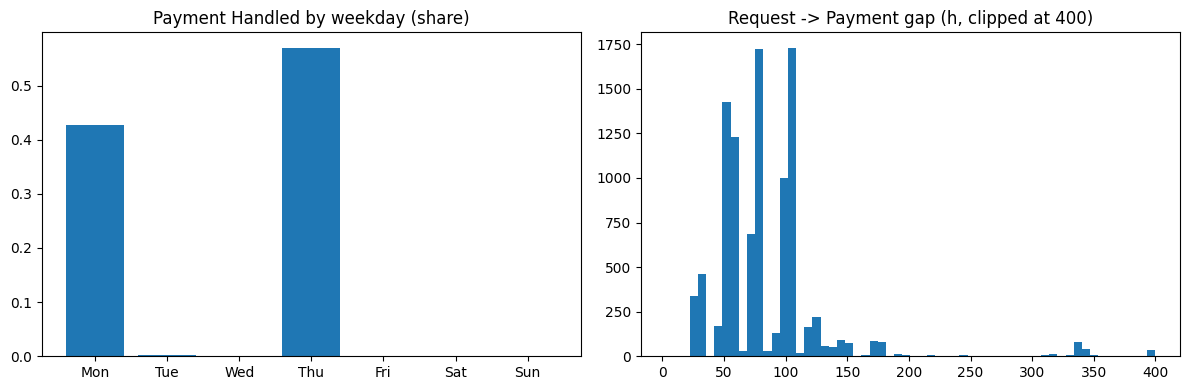

In [ ]:
# 2.4 Payment batch schedule — DERIVED from the data
pay_ev = events[events[ACTIVITY_COL] == ACT_PAYMENT].copy()
dow_share = (pay_ev[TIME_COL].dt.weekday.value_counts(normalize=True)
             .reindex(range(7), fill_value=0.0))
if BATCH_WEEKDAYS is None:
    BATCH_WEEKDAYS = sorted(int(d) for d in dow_share[dow_share >= 0.10].index)
batch_share = float(dow_share[BATCH_WEEKDAYS].sum()) if BATCH_WEEKDAYS else 0.0
BATCHED = bool(batch_share >= 0.90 and 0 < len(BATCH_WEEKDAYS) <= 3)
if BATCH_HOUR is None:
    on_batch = pay_ev[pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS)]
    BATCH_HOUR = int(on_batch[TIME_COL].dt.hour.mode().iloc[0]) if len(on_batch) else 12
if MULTI_BATCH_HRS is None:
    if BATCHED and len(BATCH_WEEKDAYS) > 1:
        d = BATCH_WEEKDAYS + [BATCH_WEEKDAYS[0] + 7]
        MULTI_BATCH_HRS = 2 * 24 * max(np.diff(d))
    elif BATCHED:
        MULTI_BATCH_HRS = 2 * 24 * 7
    else:
        MULTI_BATCH_HRS = float(req_pay_gaps.quantile(0.95))
DAYNAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Payment share by weekday:",
      {DAYNAMES[i]: round(float(v), 4) for i, v in dow_share.items()})
print(f"BATCH_WEEKDAYS={[DAYNAMES[d] for d in BATCH_WEEKDAYS]}  BATCH_HOUR={BATCH_HOUR}  "
      f"batch share={batch_share:.4f}  BATCHED={BATCHED}  MULTI_BATCH_HRS={MULTI_BATCH_HRS}")

def hours_to_next_batch_vec(ts):
    """Hours from each timestamp to the next scheduled batch slot (UTC).
    Returns zeros when the log has no batch schedule."""
    ts = pd.to_datetime(pd.Series(ts), utc=True)
    if not BATCHED:
        return pd.Series(0.0, index=ts.index)
    base = ts.dt.normalize() + pd.Timedelta(hours=BATCH_HOUR)
    best = pd.Series(pd.NaT, index=ts.index, dtype="datetime64[ns, UTC]")
    for add in range(8):
        cand = base + pd.Timedelta(days=add)
        ok = cand.dt.weekday.isin(BATCH_WEEKDAYS) & (cand > ts) & best.isna()
        best.loc[ok] = cand.loc[ok]
    return (best - ts).dt.total_seconds() / 3600

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(DAYNAMES, dow_share.values)
ax[0].set_title("Payment Handled by weekday (share)")
ax[1].hist(req_pay_gaps.clip(upper=400), bins=60)
ax[1].set_title("Request -> Payment gap (h, clipped at 400)")
save_fig("02_payment_batching")

derived = {"BATCH_WEEKDAYS": BATCH_WEEKDAYS, "BATCH_HOUR": BATCH_HOUR,
           "BATCHED": BATCHED, "batch_share": batch_share,
           "MULTI_BATCH_HRS": float(MULTI_BATCH_HRS),
           "median_req_to_pay_h": float(req_pay_gaps.median()) if len(req_pay_gaps) else None}
json.dump(derived, open(f"{RESULT_DIR}/02_derived_constants.json", "w"), indent=2)


In [ ]:
# 2.5 Prefix-length structure + bucket density (prefix space)
cases_reaching_k = events.groupby("event_idx")[CASE_COL].nunique()
prefix_table = pd.DataFrame({"k": cases_reaching_k.index,
                             "cases_reaching_k": cases_reaching_k.values})
prefix_table["share_%"] = (prefix_table["cases_reaching_k"] / phase1["cases"] * 100).round(1)
prefix_table.to_csv(f"{RESULT_DIR}/02_prefix_lengths.csv", index=False)
print(prefix_table.head(12).to_string(index=False))
bucket_density = events["event_idx"].map(bucket_of).value_counts().reindex(BUCKETS)
print("\nPrefixes per bucket:", bucket_density.to_dict())
for b, n in bucket_density.items():
    if n < MIN_PREFIXES_PER_BUCKET:
        print(f"WARNING: bucket {b} has {n} prefixes (< {MIN_PREFIXES_PER_BUCKET}); "
              f"consider changing BUCKET_EDGES.")


 k  cases_reaching_k  share_%
 1             10500    100.0
 2             10366     98.7
 3             10361     98.7
 4             10135     96.5
 5              8691     82.8
 6              3490     33.2
 7               997      9.5
 8               918      8.7
 9               505      4.8
10               207      2.0
11               122      1.2
12                69      0.7

Prefixes per bucket: {'1-3': 31227, '4-5': 18826, '6+': 6384}


In [ ]:
# 2.6 Case skeleton
grp = events.groupby(CASE_COL)
skel = grp.agg(start_time=(TIME_COL, "min"), end_time=(TIME_COL, "max"),
               length=("event_idx", "max"), amount=(AMOUNT_COL, "first"))
skel["duration_h"] = ((skel.end_time - skel.start_time).dt.total_seconds() / 3600).round(2)
skel["variant"] = variant
skel["n_request_payment"] = (events[ACTIVITY_COL] == ACT_REQUEST).groupby(events[CASE_COL]).sum()
skel["n_payment_handled"] = (events[ACTIVITY_COL] == ACT_PAYMENT).groupby(events[CASE_COL]).sum()
skel = skel.join(per_case)
skel["has_missing_role"] = (events[ROLE_COL] == "MISSING").groupby(events[CASE_COL]).any()
skel["reaches_payment"] = skel["n_payment_handled"] > 0
skel = skel.reset_index()
pass  # v5: v2 file not rewritten
print("Case skeleton:", skel.shape)


Case skeleton: (10500, 15)


In [ ]:
# 2.7 Payment structure: duplicates, bypasses, off-batch, never-paid, delays
max_pay = int(skel.n_payment_handled.max())
max_req = int(skel.n_request_payment.max())
pay_no_req = skel[(skel.n_payment_handled > 0) & (skel.n_request_payment == 0)]
req_no_pay = skel[(skel.n_request_payment > 0) & (skel.n_payment_handled == 0)]
if BATCHED:
    off_ids = set(pay_ev.loc[~pay_ev[TIME_COL].dt.weekday.isin(BATCH_WEEKDAYS), CASE_COL])
else:
    off_ids = set()
off_batch = skel[skel[CASE_COL].isin(off_ids)]
never_paid = skel[~skel.reaches_payment]
gap_case = (ev_seq[(ev_seq[ACTIVITY_COL] == ACT_REQUEST) & (ev_seq["next_act"] == ACT_PAYMENT)]
            .set_index(CASE_COL)["gap_h"])
delayed = skel[skel[CASE_COL].isin(gap_case[gap_case > MULTI_BATCH_HRS].index)]
heavy_rework = skel[skel.n_rework_loops >= HEAVY_REWORK_LOOPS]

print(f"Max Payment Handled per case: {max_pay} | max Request Payment per case: {max_req}")
print("Payment WITHOUT request (natural bypass):", len(pay_no_req))
print("Request WITHOUT payment                 :", len(req_no_pay))
print("Off-batch payment cases                 :", len(off_batch))
print(f"Never-paid cases: {len(never_paid)} "
      f"(rejected-terminal {int((never_paid.n_rejections > 0).sum())}, "
      f"abandoned {int((never_paid.n_rejections == 0).sum())})")
print(f"Multi-batch delayed (> {MULTI_BATCH_HRS} h)    :", len(delayed))
print(f"Heavy rework (>= {HEAVY_REWORK_LOOPS} loops)          :", len(heavy_rework))
for name, df_ in [("pay_without_request", pay_no_req), ("request_without_pay", req_no_pay),
                  ("off_batch_payments", off_batch), ("never_paid", never_paid),
                  ("multi_batch_delayed", delayed), ("heavy_rework", heavy_rework)]:
    df_.to_csv(f"{RESULT_DIR}/02_{name}.csv", index=False)


Max Payment Handled per case: 1 | max Request Payment per case: 1
Payment WITHOUT request (natural bypass): 7
Request WITHOUT payment                 : 3
Off-batch payment cases                 : 27
Never-paid cases: 456 (rejected-terminal 322, abandoned 134)
Multi-batch delayed (> 180 h)    : 230
Heavy rework (>= 2 loops)          : 126


In [ ]:
# 2.8 Cross-case rare-amount clusters (rarity filter + cluster chaining + payment time)
pay_time = pay_ev.groupby(CASE_COL)[TIME_COL].first().rename("pay_time")
amt2 = (skel.set_index(CASE_COL)[["amount"]].join(pay_time, how="inner")
        .reset_index().dropna())
amount_freq_all = skel["amount"].value_counts()
amt2["is_rare"] = amt2["amount"].map(amount_freq_all).le(RARE_AMOUNT_MAX)
amt2 = amt2.sort_values(["amount", "pay_time"])
amt2["gap_d"] = amt2.groupby("amount")["pay_time"].diff().dt.total_seconds() / 86400
amt2["cluster_id"] = (amt2["gap_d"].isna() | (amt2["gap_d"] > REPEAT_WINDOW_D)).cumsum()
clusters = amt2.groupby("cluster_id").agg(
    amount=("amount", "first"), n_cases=(CASE_COL, "nunique"), rare=("is_rare", "first"),
    first_pay=("pay_time", "min"), last_pay=("pay_time", "max"))
clusters["same_instant"] = clusters["first_pay"] == clusters["last_pay"]
rare_clusters = clusters[(clusters.n_cases >= 2) & clusters.rare]
member = amt2.merge(rare_clusters[[]], left_on="cluster_id", right_index=True)
RARE_CLUSTER_CASES = set(member[CASE_COL])
print("Multi-case clusters within window:", int((clusters.n_cases >= 2).sum()))
print("Rare-amount clusters:", len(rare_clusters), "| cases:", len(RARE_CLUSTER_CASES),
      "| same-instant:", int(rare_clusters.same_instant.sum()))
rare_clusters.to_csv(f"{RESULT_DIR}/02_rare_amount_clusters.csv")
pd.Series(sorted(RARE_CLUSTER_CASES), name=CASE_COL).to_csv(
    f"{RESULT_DIR}/02_rare_cluster_cases.csv", index=False)


Multi-case clusters within window: 285
Rare-amount clusters: 123 | cases: 253 | same-instant: 105


In [ ]:
# 2.9 Track-B PRE-REGISTRATION (frozen before any model exists)
TRACKB = {
    "C1_payment_without_request": set(pay_no_req[CASE_COL]),
    "C2_off_batch_payment": set(off_batch[CASE_COL]),
    "C3_rare_amount_cluster": RARE_CLUSTER_CASES,
    "C4_multi_batch_delay": set(delayed[CASE_COL]),
    "C5_heavy_rework": set(heavy_rework[CASE_COL]),
}
def _write_prereg(path):
    lines = [f"# Track-B pre-registration — {LOG_NAME}",
             f"Frozen: {datetime.datetime.now().isoformat(timespec='seconds')}",
             "Written BEFORE any detector was trained. Criteria and thresholds:",
             f"- C1 payment without request (n={len(TRACKB['C1_payment_without_request'])})",
             f"- C2 payment outside batch weekdays {[DAYNAMES[d] for d in BATCH_WEEKDAYS]} "
             f"(n={len(TRACKB['C2_off_batch_payment'])})",
             f"- C3 rare amount (in <= {RARE_AMOUNT_MAX} cases) repeated across cases paid "
             f"within {REPEAT_WINDOW_D} days (n={len(RARE_CLUSTER_CASES)})",
             f"- C4 request->payment gap > {MULTI_BATCH_HRS} h (n={len(TRACKB['C4_multi_batch_delay'])})",
             f"- C5 >= {HEAVY_REWORK_LOOPS} rework loops (n={len(TRACKB['C5_heavy_rework'])})",
             "Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators "
             "from different perspectives; 1 indicator = weak support.",
             "Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); "
             "plausibility is reported with and without overlap cases."]
    open(path, "w").write("\n".join(lines))
write_frozen(f"{FROZEN_DIR}/trackB_preregistration.md", _write_prereg)
print(open(f"{FROZEN_DIR}/trackB_preregistration.md").read())

audit = {"max_pay_per_case": max_pay, "pay_without_request": len(pay_no_req),
         "request_without_pay": len(req_no_pay), "off_batch_cases": len(off_batch),
         "never_paid": len(never_paid), "rare_clusters": len(rare_clusters),
         "rare_cluster_cases": len(RARE_CLUSTER_CASES), "delayed": len(delayed),
         "heavy_rework": len(heavy_rework), "variants": len(variant_counts), **derived}
pd.DataFrame([audit]).to_csv(f"{RESULT_DIR}/02_audit_summary.csv", index=False)


FROZEN (kept existing): trackB_preregistration.md
# Track-B pre-registration — BPIC20_D
Frozen: 2026-10-03T08:16:09
Written BEFORE any detector was trained. Criteria and thresholds:
- C1 payment without request (n=7)
- C2 payment outside batch weekdays [] (n=0)
- C3 rare amount (in <= 3 cases) repeated across cases paid within 7 days (n=253)
- C4 request->payment gap > 180 h (n=230)
- C5 >= 2 rework loops (n=126)
Verdict rule: 'domain-supported suspicious' = >= 2 independent indicators from different perspectives; 1 indicator = weak support.
Overlap disclosure: C1, C2, C3, C4 and C5 also exist as F-rules (F6, F7, F3, F8, F9); plausibility is reported with and without overlap cases.


In [ ]:
# 3.1 Train / val / test split by case (FROZEN)
from sklearn.model_selection import train_test_split
SPLIT_PATH = f"{FROZEN_DIR}/case_split.csv"
def _write_split(path):
    ids, strat = skel[CASE_COL], skel["reaches_payment"]
    tr, tmp = train_test_split(ids, test_size=1 - SPLIT[0],
                               random_state=RANDOM_SEED, stratify=strat)
    va, te = train_test_split(tmp, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                              random_state=RANDOM_SEED, stratify=strat.loc[tmp.index])
    out = pd.DataFrame({CASE_COL: ids, "split": "train"})
    out.loc[out[CASE_COL].isin(va), "split"] = "val"
    out.loc[out[CASE_COL].isin(te), "split"] = "test"
    out.to_csv(path, index=False)
write_frozen(SPLIT_PATH, _write_split)
split_map = pd.read_csv(SPLIT_PATH, dtype={CASE_COL: str}).set_index(CASE_COL)["split"]
events["split"] = events[CASE_COL].map(split_map)
skel["split"] = skel[CASE_COL].map(split_map)
assert events["split"].notna().all(), "cases missing from the frozen split"
print(skel["split"].value_counts().to_dict())
print("reaches_payment share:", skel.groupby("split")["reaches_payment"].mean().round(4).to_dict())


FROZEN (kept existing): case_split.csv
{'train': 6300, 'val': 2100, 'test': 2100}
reaches_payment share: {'test': 0.9567, 'train': 0.9565, 'val': 0.9567}


In [ ]:
# 3.2 Feature builder — ONE function for the natural and the injected world.
# SET B (behavioural) + SET S (state): no money. SET F: money, consequence lane only.
def build_features(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True).copy()
    ev[TIME_COL] = pd.to_datetime(ev[TIME_COL], utc=True)
    ev["prefix_key"] = (ev.groupby(CASE_COL)[ACTIVITY_COL]
                        .transform(lambda s: (s + "|").cumsum().str[:-1]))
    ev["prev_act"] = ev.groupby(CASE_COL)[ACTIVITY_COL].shift(1)
    tr = ev["split"] == "train"                     # train-only statistic maps
    pf_map = ev.loc[tr, "prefix_key"].value_counts()
    tf_map = ev[tr & ev["prev_act"].notna()].groupby(["prev_act", ACTIVITY_COL]).size()
    rare_cut = tf_map.sum() * 0.001
    tr_amt = ev[tr].groupby(CASE_COL)[AMOUNT_COL].first().dropna()
    amt_freq, amt_sorted = tr_amt.value_counts(), np.sort(tr_amt.values)

    p = ev[[CASE_COL, ACTIVITY_COL, TIME_COL, ROLE_COL, "event_idx", "split",
            "prefix_key", "prev_act"]].copy()
    g = p.groupby(CASE_COL)
    p["B_len"] = p["event_idx"]
    p["B_n_unique_acts"] = g[ACTIVITY_COL].transform(lambda s: (~s.duplicated()).cumsum())
    p["B_unique_ratio"] = p["B_n_unique_acts"] / p["B_len"]
    p["B_repeat_ratio"] = 1 - p["B_unique_ratio"]
    p["_s"] = p[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False).astype(int)
    p["_r"] = p[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False).astype(int)
    p["_a"] = p[ACTIVITY_COL].str.contains(APPROVE_TOKEN, regex=False).astype(int)
    p["_rs_"] = ((p["_s"] == 1) & (p.groupby([CASE_COL, ACTIVITY_COL]).cumcount() >= 1)).astype(int)
    p["B_n_submissions_so_far"] = g["_s"].cumsum()
    p["B_n_rejections_so_far"] = g["_r"].cumsum()
    p["B_n_approvals_so_far"] = g["_a"].cumsum()
    p["B_rework_loops_so_far"] = p.groupby(CASE_COL)["_rs_"].cumsum()
    pf = p["prefix_key"].map(pf_map).fillna(0.0)
    p["B_prefix_log_freq"] = np.log1p(pf)
    p["B_prefix_is_unseen"] = (pf == 0).astype(int)
    tf_ = pd.Series(tf_map.reindex(pd.MultiIndex.from_frame(p[["prev_act", ACTIVITY_COL]])).values,
                    index=p.index).fillna(0.0)
    p["_rt"] = ((tf_ < rare_cut) & p["prev_act"].notna()).astype(int)
    p["B_rare_trans_so_far"] = g["_rt"].cumsum()
    p["_rc"] = p[ROLE_COL].replace({"MISSING": "UNKNOWN_ROLE"})
    p["_rs"] = ((p["_rc"] != g["_rc"].shift(1)) & g["_rc"].shift(1).notna()).astype(int)
    p["B_role_switches_so_far"] = g["_rs"].cumsum()
    p["_mr"] = (p[ROLE_COL] == "MISSING").astype(int)
    p["B_missing_role_so_far"] = g["_mr"].cumsum().clip(upper=1)
    p["_gap"] = (p[TIME_COL] - g[TIME_COL].shift(1)).dt.total_seconds() / 3600
    p["B_dur_so_far_h"] = (p[TIME_COL] - g[TIME_COL].transform("first")).dt.total_seconds() / 3600
    p["B_mean_gap_h"] = p["B_dur_so_far_h"] / (p["B_len"] - 1).clip(lower=1)
    p["B_max_gap_h"] = p.groupby(CASE_COL)["_gap"].cummax().fillna(0.0)
    p["B_last_gap_h"] = p["_gap"].fillna(0.0)
    p["_we"] = (p[TIME_COL].dt.weekday >= 5).astype(int)
    p["_oh"] = (~p[TIME_COL].dt.hour.between(8, 18)).astype(int)
    p["B_weekend_ratio_so_far"] = g["_we"].cumsum() / p["B_len"]
    p["B_offhours_ratio_so_far"] = g["_oh"].cumsum() / p["B_len"]
    p["_ir"] = (p[ACTIVITY_COL] == ACT_REQUEST).astype(int)
    p["_ip"] = (p[ACTIVITY_COL] == ACT_PAYMENT).astype(int)
    p["S_n_requests_so_far"] = g["_ir"].cumsum()
    p["S_n_payments_so_far"] = g["_ip"].cumsum()
    p["S_request_seen"] = (p["S_n_requests_so_far"] > 0).astype(int)
    p["S_payment_seen"] = (p["S_n_payments_so_far"] > 0).astype(int)
    p["_rtf"] = p[TIME_COL].where(p["_ir"] == 1).groupby(p[CASE_COL]).ffill()
    p["S_hours_since_request"] = ((p[TIME_COL] - p["_rtf"]).dt.total_seconds() / 3600
                                  ).fillna(0.0).clip(lower=0)
    p["_bw"] = np.nan
    m = p["_ir"] == 1
    if m.any():
        p.loc[m, "_bw"] = hours_to_next_batch_vec(p.loc[m, TIME_COL]).values
    p["_bw"] = p.groupby(CASE_COL)["_bw"].ffill()
    p["B_excess_wait_h"] = (p["S_hours_since_request"] - p["_bw"]).clip(lower=0).fillna(0.0)
    p["B_multi_batch_delay"] = (p["S_hours_since_request"] > MULTI_BATCH_HRS).astype(int)
    p["S_hours_to_next_batch"] = hours_to_next_batch_vec(p[TIME_COL]).values
    # ---- SET F (consequence lane only) ----
    amt_map = ev.groupby(CASE_COL)[AMOUNT_COL].first()
    p["F_amount"] = p[CASE_COL].map(amt_map)
    p["F_log_amount"] = np.log1p(p["F_amount"].clip(lower=0))
    p["F_amount_train_freq"] = p["F_amount"].map(amt_freq).fillna(0)
    p["F_is_rare_amount"] = (p["F_amount_train_freq"] <= RARE_AMOUNT_MAX).astype(int)
    p["F_amount_pctile"] = (np.searchsorted(amt_sorted, p["F_amount"].fillna(0).values)
                            / max(len(amt_sorted), 1))
    p["F_potential_exposure"] = np.where((p["S_request_seen"] == 1) & (p["S_payment_seen"] == 0),
                                         p["F_amount"].fillna(0), 0.0)
    p["F_settled_amount"] = np.where(p["S_payment_seen"] == 1, p["F_amount"].fillna(0), 0.0)
    p["bucket"] = p["event_idx"].map(bucket_of)
    return p.drop(columns=[c for c in p.columns if c.startswith("_")] + ["prefix_key", "prev_act"])

PX_PATH = f"{FEATURE_DIR}/prefix_features.parquet"
if cached(PX_PATH):
    px = pd.read_parquet(PX_PATH)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    print("Loaded cached prefix features:", px.shape)
else:
    px = build_features(events)
    px.to_parquet(PX_PATH, index=False)
    print("Built prefix features:", px.shape)

B_COLS = [c for c in px.columns if c.startswith("B_")]
S_COLS = [c for c in px.columns if c.startswith("S_")]
F_COLS = [c for c in px.columns if c.startswith("F_")]
DETECTOR_FEATURES = B_COLS + S_COLS
leaky = [c for c in DETECTOR_FEATURES if "amount" in c.lower() or c.startswith("F_")]
assert not leaky, f"SEAL VIOLATION: {leaky}"
assert len(px) == len(events), "one row per event (= per prefix) expected"
assert px[DETECTOR_FEATURES + F_COLS].isna().sum().sum() == 0, "NaNs in features"
pd.DataFrame({"feature": B_COLS + S_COLS + F_COLS,
              "set": ["B"] * len(B_COLS) + ["S"] * len(S_COLS) + ["F"] * len(F_COLS),
              "detector_input": [True] * len(DETECTOR_FEATURES) + [False] * len(F_COLS)}
             )  # v5: v2 file not rewritten
print(f"Detector features: {len(DETECTOR_FEATURES)} | financial features: {len(F_COLS)} | seal OK")
print("Unseen-prefix share by split:", px.groupby("split")["B_prefix_is_unseen"].mean().round(4).to_dict())


Loaded cached prefix features: (56437, 41)
Detector features: 27 | financial features: 7 | seal OK
Unseen-prefix share by split: {'test': 0.0029, 'train': 0.0, 'val': 0.002}


In [ ]:
# 4.1 TensorFlow setup
import joblib
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
tf.keras.utils.set_random_seed(RANDOM_SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
train_mask = (px["split"] == "train").values


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 4.2 BASELINE 1 — Isolation Forest on tabular B+S features
IF_PATH, SCALER_PATH = f"{MODEL_DIR}/if.joblib", f"{MODEL_DIR}/scaler.joblib"
if cached(IF_PATH) and cached(SCALER_PATH):
    if_model, scaler = joblib.load(IF_PATH), joblib.load(SCALER_PATH)
    print("Loaded Isolation Forest.")
else:
    scaler = StandardScaler().fit(px.loc[train_mask, DETECTOR_FEATURES])
    if_model = IsolationForest(n_estimators=200, max_samples=256, random_state=RANDOM_SEED,
                               n_jobs=-1).fit(scaler.transform(px.loc[train_mask, DETECTOR_FEATURES]))
    joblib.dump(if_model, IF_PATH); joblib.dump(scaler, SCALER_PATH)
    print("Trained Isolation Forest.")

def score_if(p):
    return -if_model.score_samples(scaler.transform(p[DETECTOR_FEATURES]))


Loaded Isolation Forest.


In [ ]:
# 4.3 BASELINE 2 — LSTM autoencoder on activity sequences (v1 design, mean error)
AE_PATH, AE_META = f"{MODEL_DIR}/ae.keras", f"{MODEL_DIR}/ae_meta.joblib"
if cached(AE_META):
    ae_meta = joblib.load(AE_META)
else:
    acts = sorted(events.loc[events.split == "train", ACTIVITY_COL].unique())
    ae_meta = {"act2id": {a: i + 1 for i, a in enumerate(acts)}}
    ae_meta["UNK"] = len(acts) + 1
    ae_meta["VOCAB"] = len(acts) + 2
    joblib.dump(ae_meta, AE_META)
ACT2ID, AE_UNK, AE_VOCAB = ae_meta["act2id"], ae_meta["UNK"], ae_meta["VOCAB"]

def prefix_seq_matrix(ev, p):
    seqs = (ev.sort_values([CASE_COL, "event_idx"]).groupby(CASE_COL)[ACTIVITY_COL]
            .agg(lambda s: [ACT2ID.get(a, AE_UNK) for a in s]).to_dict())
    M = np.zeros((len(p), AE_MAXLEN), dtype=np.int32)
    for i, (cid, k) in enumerate(zip(p[CASE_COL].values, p["event_idx"].values)):
        ids = seqs[cid][:min(int(k), AE_MAXLEN)]
        M[i, :len(ids)] = ids
    return M

def build_ae():
    inp = layers.Input(shape=(AE_MAXLEN,), dtype="int32")
    h = layers.Embedding(AE_VOCAB, 16, mask_zero=True)(inp)
    h = layers.LSTM(64)(h)
    h = layers.RepeatVector(AE_MAXLEN)(h)
    h = layers.LSTM(64, return_sequences=True)(h)
    out = layers.TimeDistributed(layers.Dense(AE_VOCAB, activation="softmax"))(h)
    m = Model(inp, out)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    return m

def score_ae(model, M, batch=4096):
    errs = np.zeros(len(M))
    for s in range(0, len(M), batch):
        xb = M[s:s + batch]
        probs = model.predict(xb, verbose=0)
        pt = np.take_along_axis(probs, xb[..., None], axis=2)[..., 0]
        ce = -np.log(np.clip(pt, 1e-9, 1.0))
        mk = xb > 0
        errs[s:s + batch] = (ce * mk).sum(1) / np.maximum(mk.sum(1), 1)
    return errs

SEQ_NAT = prefix_seq_matrix(events, px)
if cached(AE_PATH):
    ae = tf.keras.models.load_model(AE_PATH, compile=False)
    print("Loaded autoencoder.")
else:
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    ae = build_ae()
    ae.fit(SEQ_NAT[train_mask], SEQ_NAT[train_mask], validation_split=0.1,
           epochs=AE_EPOCHS, batch_size=256, verbose=2,
           callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    ae.save(AE_PATH)


Loaded autoencoder.


In [ ]:
# 4.4 IMPROVED — multi-perspective next-event model
# Event score = -log P(activity, role, time-gap bucket | earlier events); prefix
# score = max over its events (worst event, not diluted). Causal => one pass
# scores every prefix, so it is streaming-native. No amount enters the model.
GAP_EDGES_H = [1 / 60, 1, 24, 72, 168]
PAD, BOS, UNK, EOS = 0, 1, 2, 3     # EOS teaches the model where a case ends
NE_VARIANTS = {"act": ["act"], "act_role": ["act", "role"], "full": ["act", "role", "gap"]}
NE_SCORE_COLS = [f"{agg}_{v}" for agg in ["max", "mean"] for v in NE_VARIANTS]

def add_tokens(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    gap_h = ev.groupby(CASE_COL)[TIME_COL].diff().dt.total_seconds() / 3600
    b = np.digitize(gap_h.fillna(0).values, GAP_EDGES_H) + 1
    ev["gap_tok"] = np.where(gap_h.isna().values, 0, b).astype(str)
    ev["role_tok"] = ev[ROLE_COL].fillna("NA").astype(str).replace({"MISSING": "UNKNOWN_ROLE"})
    return ev

NE_COLS = {"act": ACTIVITY_COL, "role": "role_tok", "gap": "gap_tok"}
PERSP = list(NE_COLS)
NE_META = f"{MODEL_DIR}/ne_meta.joblib"
ev_tok = add_tokens(events)
if cached(NE_META):
    VOC = joblib.load(NE_META)["VOC"]
else:
    trm = ev_tok["split"] == "train"
    VOC = {p: {v: i + 4 for i, v in enumerate(sorted(ev_tok.loc[trm, c].unique()))}
           for p, c in NE_COLS.items()}
    joblib.dump({"VOC": VOC, "GAP_EDGES_H": GAP_EDGES_H, "NE_MAXLEN": NE_MAXLEN}, NE_META)
VSIZE = {p: len(v) + 4 for p, v in VOC.items()}
print("Next-event vocab sizes:", VSIZE)

def encode_cases(ev):
    ev = ev.sort_values([CASE_COL, "event_idx"]).copy()
    for p in PERSP:
        ev[f"_{p}"] = ev[NE_COLS[p]].map(VOC[p]).fillna(UNK).astype(np.int32)
    groups = list(ev.groupby(CASE_COL, sort=True))
    n = len(groups)
    Y = {p: np.zeros((n, NE_MAXLEN), np.int32) for p in PERSP}
    lens, ids = np.zeros(n, np.int32), []
    for i, (cid, gdf) in enumerate(groups):
        ids.append(cid)
        lens[i] = len(gdf)
        L = min(len(gdf), NE_MAXLEN - 1)          # leave room for EOS
        for p in PERSP:
            Y[p][i, :L] = gdf[f"_{p}"].values[:L]
            if len(gdf) <= NE_MAXLEN - 1:
                Y[p][i, L] = EOS                   # target after the last event
    X = {p: np.concatenate([np.full((n, 1), BOS, np.int32), Y[p][:, :-1]], 1) for p in PERSP}
    return np.array(ids), X, Y, lens

def masked_sce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    m = tf.cast(y_true > 0, ce.dtype)
    return tf.reduce_sum(ce * m) / tf.maximum(tf.reduce_sum(m), 1.0)

def build_ne(hidden=128, drop=0.1):
    dims = {"act": 32, "role": 8, "gap": 8}
    ins = [layers.Input((NE_MAXLEN,), dtype="int32", name=f"in_{p}") for p in PERSP]
    embs = [layers.Embedding(VSIZE[p], dims[p])(i) for p, i in zip(PERSP, ins)]
    h = layers.Dropout(drop)(layers.Concatenate()(embs))
    h = layers.LSTM(hidden, return_sequences=True)(h)
    h = layers.Dropout(drop)(h)
    h = layers.LSTM(hidden, return_sequences=True)(h)
    outs = [layers.Dense(VSIZE[p], activation="softmax", name=f"out_{p}")(h) for p in PERSP]
    m = Model(ins, outs)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=[masked_sce] * len(PERSP))
    return m

def train_ne(ev_tokens_train, seed, verbose=2):
    tf.keras.utils.set_random_seed(seed)
    _, X, Y, _ = encode_cases(ev_tokens_train)
    idx = np.random.default_rng(seed).permutation(len(Y["act"]))
    cut = int(0.9 * len(idx))
    a, b = idx[:cut], idx[cut:]
    m = build_ne()
    m.fit([X[p][a] for p in PERSP], [Y[p][a] for p in PERSP],
          validation_data=([X[p][b] for p in PERSP], [Y[p][b] for p in PERSP]),
          epochs=NE_EPOCHS, batch_size=128, verbose=verbose,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m

def ne_event_scores(model, ev_tokens):
    """Per-event NLL per perspective + prefix scores (max/mean x variants)."""
    cids, X, Y, lens = encode_cases(ev_tokens)
    probs = model.predict([X[p] for p in PERSP], batch_size=512, verbose=0)
    mask = np.arange(NE_MAXLEN)[None, :] < np.minimum(lens, NE_MAXLEN - 1)[:, None]  # real events only
    ci, ti = np.nonzero(mask)
    d = pd.DataFrame({CASE_COL: cids[ci], "event_idx": ti + 1})
    for p, pr in zip(PERSP, probs):
        pt = np.take_along_axis(pr, Y[p][..., None], axis=2)[..., 0]
        d[f"nll_{p}"] = -np.log(np.clip(pt[ci, ti], 1e-9, 1.0))
    for v, parts in NE_VARIANTS.items():
        e = d[[f"nll_{p}" for p in parts]].sum(axis=1)
        d[f"e_{v}"] = e
        d[f"max_{v}"] = e.groupby(d[CASE_COL]).cummax()
        d[f"mean_{v}"] = e.groupby(d[CASE_COL]).cumsum() / d["event_idx"]
    return d

NE_PATH = f"{MODEL_DIR}/next_event.keras"
if cached(NE_PATH):
    ne_model = tf.keras.models.load_model(NE_PATH, compile=False)
    print("Loaded next-event model.")
else:
    ne_model = train_ne(ev_tok[ev_tok.split == "train"], RANDOM_SEED)
    ne_model.save(NE_PATH)


Next-event vocab sizes: {'act': 20, 'role': 11, 'gap': 11}
Loaded next-event model.


In [ ]:
# 4.5 Score the natural log with every detector; per-bucket calibration on TRAIN
RAW_TO_A = {"raw_IF": "A_IF", "raw_AE": "A_AE",
            **{c: f"A_NE_{c}" for c in NE_SCORE_COLS}}

def score_detectors(ev, p, model=None, seq=None):
    """Adds raw detector scores to prefix table p (rows aligned by case, event_idx)."""
    model = model or ne_model
    out = p.copy()
    out["raw_IF"] = score_if(out)
    out["raw_AE"] = score_ae(ae, seq if seq is not None else prefix_seq_matrix(ev, out))
    ne = ne_event_scores(model, add_tokens(ev))
    out = out.merge(ne[[CASE_COL, "event_idx"] + NE_SCORE_COLS],
                    on=[CASE_COL, "event_idx"], how="left")
    out[NE_SCORE_COLS] = out.groupby(CASE_COL)[NE_SCORE_COLS].ffill()   # beyond NE_MAXLEN
    return out, ne

def fit_refs(p, mask):
    return {f"{c}|{b}": np.sort(p.loc[mask & (p["bucket"] == b).values, c].values)
            for c in RAW_TO_A for b in BUCKETS}

def apply_refs(p, refs):
    for raw, a in RAW_TO_A.items():
        out = np.zeros(len(p))
        for b in BUCKETS:
            m = (p["bucket"] == b).values
            out[m] = midpoint_rank(p.loc[m, raw].values, refs[f"{raw}|{b}"])
        p[a] = out
    p["A_ENS"] = (p["A_IF"] + p["A_AE"]) / 2           # v1 anomaly lane
    return p

NAT_SCORES = f"{FEATURE_DIR}/natural_scores.parquet"
NAT_NE_EV = f"{FEATURE_DIR}/natural_ne_events.parquet"
REFS_PATH = f"{MODEL_DIR}/calibration_refs.joblib"
if cached(NAT_SCORES) and cached(NAT_NE_EV) and cached(REFS_PATH):
    px = pd.read_parquet(NAT_SCORES)
    px[TIME_COL] = pd.to_datetime(px[TIME_COL], utc=True)
    ne_nat = pd.read_parquet(NAT_NE_EV)
    REFS = joblib.load(REFS_PATH)
    print("Loaded cached natural scores.")
else:
    px, ne_nat = score_detectors(events, px, seq=SEQ_NAT)
    REFS = fit_refs(px, train_mask)
    px = apply_refs(px, REFS)
    joblib.dump(REFS, REFS_PATH)
    ne_nat.to_parquet(NAT_NE_EV, index=False)
    px.to_parquet(NAT_SCORES, index=False)
A_NE_COLS = [f"A_NE_{c}" for c in NE_SCORE_COLS]
A_ALL = ["A_IF", "A_AE", "A_ENS"] + A_NE_COLS
print("Calibrated means by split (train = 0.50 by construction):")
print(px.groupby("split")[A_ALL].mean().round(3).T.to_string())
print("\nCorrelations: IF~AE %.3f | AE~NE(max_full) %.3f" % (
    px["A_IF"].corr(px["A_AE"]), px["A_AE"].corr(px["A_NE_max_full"])))


Loaded cached natural scores.
Calibrated means by split (train = 0.50 by construction):
split                test  train    val
A_IF                0.489    0.5  0.497
A_AE                0.494    0.5  0.501
A_ENS               0.492    0.5  0.499
A_NE_max_act        0.495    0.5  0.501
A_NE_max_act_role   0.494    0.5  0.499
A_NE_max_full       0.496    0.5  0.499
A_NE_mean_act       0.495    0.5  0.502
A_NE_mean_act_role  0.495    0.5  0.500
A_NE_mean_full      0.496    0.5  0.502

Correlations: IF~AE 0.540 | AE~NE(max_full) 0.496


In [ ]:
# 5.1 Rule registry v1 (FROZEN before fusion tuning and Track-B review)
REG_PATH = f"{FROZEN_DIR}/rule_registry_v1.json"
def _write_registry(path):
    reg = {"version": "1.0", "log": LOG_NAME,
           "frozen": datetime.datetime.now().isoformat(timespec="seconds"),
           "thresholds": {"batched": BATCHED, "batch_weekdays": BATCH_WEEKDAYS,
                          "batch_hour": BATCH_HOUR, "multi_batch_hrs": float(MULTI_BATCH_HRS),
                          "repeat_window_d": REPEAT_WINDOW_D, "rare_amount_max": RARE_AMOUNT_MAX,
                          "heavy_rework_loops": HEAVY_REWORK_LOOPS},
           "rules": {
               "F1": {"name": "Duplicate payment in case", "consequence": "loss", "severity": 3,
                      "survey_type": "rework", "source": "audit practice"},
               "F2": {"name": "Repeated payment request", "consequence": "exposure", "severity": 3,
                      "survey_type": "insert", "source": "audit practice"},
               "F3": {"name": "Rare amount in cross-case payment cluster", "consequence": "exposure",
                      "severity": 2, "survey_type": "attribute", "source": "audit + data"},
               "F6": {"name": "Payment without request (bypass)", "consequence": "exposure",
                      "severity": 3, "survey_type": "skip", "source": "audit practice"},
               "F7": {"name": "Off-batch payment", "consequence": "exposure", "severity": 2,
                      "survey_type": "attribute", "source": "data-derived"},
               "F8": {"name": "Multi-batch payment delay", "consequence": "exposure", "severity": 1,
                      "survey_type": "late", "source": "data-derived"},
               "F9": {"name": "Heavy rework reaching payment", "consequence": "exposure",
                      "severity": 1, "survey_type": "rework", "source": "data-derived"},
               "F10": {"name": "New request after an existing payment", "consequence": "exposure",
                       "severity": 3, "survey_type": "insert", "source": "audit practice"}},
           "omitted": {"F4": "within-case amount repeat impossible (one amount per case); folded into F3",
                       "F5": "amount inflation: no adjusted-amount field; Track A only (A3 not injected)"}}
    json.dump(reg, open(path, "w"), indent=2)
write_frozen(REG_PATH, _write_registry)
REG = json.load(open(REG_PATH))
RULES = list(REG["rules"])
print("Registry frozen on", REG["frozen"], "| rules:", RULES)


FROZEN (kept existing): rule_registry_v1.json
Registry frozen on 2026-10-03T08:23:10 | rules: ['F1', 'F2', 'F3', 'F6', 'F7', 'F8', 'F9', 'F10']


In [ ]:
# 5.2 Rule engine (prefix-computable) + F calibration on natural TRAIN prefixes
def apply_rules(p):
    th = REG["thresholds"]
    is_req = p[ACTIVITY_COL] == ACT_REQUEST
    is_pay = p[ACTIVITY_COL] == ACT_PAYMENT
    h = pd.DataFrame(index=p.index)
    h["F1"] = p["S_n_payments_so_far"] >= 2
    h["F2"] = p["S_n_requests_so_far"] >= 2
    h["F3"] = p[CASE_COL].isin(RARE_CLUSTER_CASES) & (p["S_payment_seen"] == 1)
    h["F6"] = (p["S_payment_seen"] == 1) & (p["S_n_requests_so_far"] == 0)
    if th["batched"]:
        offb = (is_pay & ~p[TIME_COL].dt.weekday.isin(th["batch_weekdays"])).astype(int)
        h["F7"] = offb.groupby(p[CASE_COL]).cummax() > 0
    else:
        h["F7"] = False
    h["F8"] = p["S_hours_since_request"] > th["multi_batch_hrs"]
    h["F9"] = (p["B_rework_loops_so_far"] >= th["heavy_rework_loops"]) & (p["S_payment_seen"] == 1)
    rap = (is_req & (p["S_n_payments_so_far"] >= 1)).astype(int)
    h["F10"] = rap.groupby(p[CASE_COL]).cummax() > 0
    h = h[RULES].astype(int)
    sev = sum(h[r] * REG["rules"][r]["severity"] for r in RULES)
    loss_rules = [r for r in RULES if REG["rules"][r]["consequence"] == "loss"]
    amt = p["F_amount"].fillna(0).clip(lower=0).values
    actual = np.where(h[loss_rules].sum(axis=1).values > 0, amt, 0.0)
    expo = np.where((sev.values > 0) & (actual == 0), amt, 0.0)
    out = p.copy()
    for r in RULES:
        out[f"hit_{r}"] = h[r].values
    out["severity_sum"] = sev.values
    out["n_rules_fired"] = h.sum(axis=1).values
    out["actual_loss"], out["potential_exposure"] = actual, expo
    out["money_at_risk"] = actual + expo
    out["F_raw"] = np.log1p(out["money_at_risk"]) * out["severity_sum"]
    return out

def apply_F(p):
    p["F"] = 0.0
    pos = p["F_raw"] > 0
    p.loc[pos, "F"] = midpoint_rank(p.loc[pos, "F_raw"].values, F_REF)
    return p

px = apply_rules(px)
F_REF = np.sort(px.loc[train_mask & (px["F_raw"] > 0).values, "F_raw"].values)
pass  # v5: v2 file not rewritten
px = apply_F(px)
print("Natural rule firings (prefixes):", {r: int(px[f"hit_{r}"].sum()) for r in RULES})
print("Prefixes with >=1 rule:", int((px.n_rules_fired > 0).sum()),
      "| F train-ref size:", len(F_REF))
pass  # v5: v2 file not rewritten


Natural rule firings (prefixes): {'F1': 0, 'F2': 0, 'F3': 253, 'F6': 7, 'F7': 0, 'F8': 232, 'F9': 123, 'F10': 0}
Prefixes with >=1 rule: 602 | F train-ref size: 366


In [ ]:
# 6.1 Injection engine — dtype-safe, batch-conformant, deterministic
REQ_PAY_POOL = req_pay_gaps.values if len(req_pay_gaps) else np.array([72.0])
APPROVALS = [a for a in events[ACTIVITY_COL].unique() if APPROVE_TOKEN in a]

def _next_slot(after_ts, rng):
    if BATCHED:
        base = after_ts.normalize()
        for add in range(9):
            cand = base + pd.Timedelta(days=add, hours=BATCH_HOUR,
                                       minutes=int(rng.integers(0, 60)))
            if cand.weekday() in BATCH_WEEKDAYS and cand > after_ts:
                return cand
    return after_ts + pd.Timedelta(hours=float(rng.choice(REQ_PAY_POOL)))

def _inject_case(cdf, itype, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True)
    cdf["_inj"] = 0
    amt = float(cdf[AMOUNT_COL].iloc[0])
    pay_i = cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]
    req_i = cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST]
    gt = {"type": itype, "amount": amt, "loss": 0.0, "exposure": 0.0}
    if itype == "A1":                                    # duplicate payment
        new = cdf.loc[[pay_i[-1]]].copy()
        new[TIME_COL] = _next_slot(cdf.loc[pay_i[-1], TIME_COL], rng)
        new["_inj"] = 1
        cdf = pd.concat([cdf, new], ignore_index=True)
        gt["loss"] = amt
    elif itype in ("A2", "A4"):                          # duplicate request (+ payment)
        new_r = cdf.loc[[req_i[-1]]].copy()
        new_r[TIME_COL] = cdf.loc[pay_i[-1], TIME_COL] + pd.Timedelta(hours=float(rng.uniform(24, 120)))
        new_r["_inj"] = 1
        parts = [cdf, new_r]
        if itype == "A4":
            new_p = cdf.loc[[pay_i[-1]]].copy()
            new_p[TIME_COL] = _next_slot(new_r[TIME_COL].iloc[0], rng)
            new_p["_inj"] = 2
            parts.append(new_p)
            gt["loss"] = amt
        else:
            gt["exposure"] = amt
        cdf = pd.concat(parts, ignore_index=True)
    elif itype == "A5":                                  # approval bypass (skip)
        cdf = cdf[~cdf[ACTIVITY_COL].isin(APPROVALS)].reset_index(drop=True)
        gt["exposure"] = amt
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    if itype == "A1":
        a = l = int(cdf.index[cdf["_inj"] == 1][0])
    elif itype == "A2":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), None
    elif itype == "A4":
        a, l = int(cdf.index[cdf["_inj"] == 1][0]), int(cdf.index[cdf["_inj"] == 2][0])
    else:
        a = int(cdf.index[cdf[ACTIVITY_COL] == ACT_REQUEST][0])
        l = int(cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT][0])
    gt["anomaly_pos"] = a + 1
    gt["loss_pos"] = None if l is None else l + 1
    gt["anomaly_time"] = cdf.loc[a, TIME_COL]
    gt["loss_time"] = None if l is None else cdf.loc[l, TIME_COL]
    return cdf.drop(columns="_inj"), gt

def inject_world(ev, target_splits, rate, seed):
    rng = np.random.default_rng(seed)
    targets = {}
    for sp in target_splits:
        n_split = int((skel["split"] == sp).sum())
        pool = skel[(skel["split"] == sp) & skel["reaches_payment"] &
                    (skel["n_request_payment"] >= 1) & (skel["n_approvals"] >= 1) &
                    (skel["length"] >= 4)]
        chosen = pool.sample(n=min(int(round(rate * n_split)), len(pool)),
                             random_state=seed)[CASE_COL].tolist()
        rng.shuffle(chosen)
        for i, cid in enumerate(chosen):
            targets[cid] = INJ_TYPES[i % len(INJ_TYPES)]
    tgt = sorted(targets)
    by_case = {cid: g for cid, g in ev[ev[CASE_COL].isin(tgt)].groupby(CASE_COL)}
    mods, gts = [], []
    for cid in tgt:
        cdf, gt = _inject_case(by_case[cid].copy(), targets[cid], rng)
        gt[CASE_COL], gt["split"] = cid, split_map[cid]
        mods.append(cdf); gts.append(gt)
    out = pd.concat([ev[~ev[CASE_COL].isin(tgt)]] + mods, ignore_index=True)
    out = out.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    out[TIME_COL] = pd.to_datetime(out[TIME_COL], utc=True)
    out["event_idx"] = out["event_idx"].astype(int)
    out[AMOUNT_COL] = pd.to_numeric(out[AMOUNT_COL], errors="coerce")
    gt = pd.DataFrame(gts)
    gt["gt_money"] = gt["loss"] + gt["exposure"]
    return out, gt

INJ_SEED = RANDOM_SEED
events_inj, gt_new = inject_world(events, ["val", "test"], INJ_RATE, INJ_SEED)
GT_PATH = f"{FROZEN_DIR}/ground_truth_sealed.csv"
write_frozen(GT_PATH, lambda path: gt_new.to_csv(path, index=False))
gt = pd.read_csv(GT_PATH, dtype={CASE_COL: str})
same = (set(zip(gt[CASE_COL], gt["type"])) == set(zip(gt_new[CASE_COL], gt_new["type"])))
assert same, ("Regenerated injection differs from the frozen ground truth. Do not change "
              "INJ_RATE/RANDOM_SEED/INJ_TYPES after freezing, or set FORCE_REFREEZE=True.")
gt = gt_new                                       # identical; keeps typed timestamps
pass  # v5: v2 file not rewritten
print("Injected cases:", len(gt), gt["type"].value_counts().to_dict(),
      "| GT money:", round(gt["gt_money"].sum(), 2),
      "| events:", len(events), "->", len(events_inj))


FROZEN (kept existing): ground_truth_sealed.csv
Injected cases: 210 {'A1': 54, 'A4': 52, 'A2': 52, 'A5': 52} | GT money: 20804.54 | events: 56437 -> 56533


## Part C · v5: benchmark detectors on the realistic worlds, with and without the financial layer
Detectors: **our next-event LSTM**, **GAMA** and **DAE** (both from the Guan et al. benchmark).

**Same footing for every detector**
- trained on the same clean TRAIN cases only (no injected anomalies, no labels, no amounts);
- the same three inputs per event: activity, role and time-gap band (the LSTM's inputs);
- their published default settings (GAMA 20 epochs; DAE 100 epochs, batch 64); nothing tuned on validation;
- scored on the same three test worlds (seeds as in v4, so the worlds are identical);
- turned into P(anomaly) by the same procedure (robust z-score against TRAIN cases of similar
  length, then Platt scaling on validation).

GAMA and DAE run in separate Python processes, so their memory is released after each run.


In [ ]:
# C.0 v5 configuration and pre-registration
import time, gc, glob, gzip, subprocess, sys
from scipy.stats import wilcoxon
SEEDS = [int(s) for s in os.environ.get("V5_SEEDS", os.environ.get("V4_SEEDS", "404,505,606")).split(",")]
V4_SEEDS = SEEDS
DETECTORS = ["LSTM", "GAMA", "DAE"]
LSTM_RAW = "max_full"                 # LSTM variant fixed in advance: worst event over activity+role+gap
GAMA_EPOCHS = int(os.environ.get("V5_GAMA_EPOCHS", 20))
DAE_EPOCHS = int(os.environ.get("V5_DAE_EPOCHS", 100))
BPAD_DIR = os.environ.get("BPAD_DIR", "/content/BPAD" if IN_COLAB else os.path.abspath("BPAD"))
COSTLY_RATE, DECOY_RATIO_MAX, RATIOS = 0.03, 10, [0, 1, 4, 10]
K, REVIEW_COSTS, K_GRID = 50, [10, 25, 50, 100], [10, 20, 30, 50, 75, 100, 150, 200]
B_SELECT, B_CI = 200, 1000
LAMBDAS, TRANSFORMS, PR_FLOOR, OTHER_RULE_WEIGHT = [0, 0.25, 0.5, 1, 2, 4, 8], ["log", "linear"], 0.02, 0.5
DUP_WINDOW_D, SPLIT_WINDOW_D = 60, 7
COSTLY_TYPES_ALL = ["A1", "A5", "C1", "C2", "C3", "C4"]
DECOY_TYPES = ["D1", "D2", "D3", "D4"]
EXPLORE_FRAC = 0.2                    # share of the review budget kept for the detector's top cases
RULE_FOR = {"A1": "F1", "A5": "F11", "C1": "F12", "C2": "F15", "C3": "F13", "C4": "F14"}
os.makedirs(V5_DIR, exist_ok=True)

PREREG_V5 = f"""# FCA-PAD v5 pre-registration (benchmark detectors + financial layer)
Written: {{written}}   Log: {LOG_NAME}
Worlds: the v4 generator, seeds {SEEDS} (identical worlds to v4).
Detectors: LSTM (variant {LSTM_RAW}, fixed), GAMA ({GAMA_EPOCHS} epochs), DAE ({DAE_EPOCHS} epochs, batch 64).
Same footing: TRAIN cases only; inputs activity, role, time-gap band; defaults; no tuning on VAL.
Calibration (all detectors): robust z vs TRAIN cases in the same length bucket; Platt on VAL (any anomaly).
Systems per detector: alone; × amount; + layer (rules v1); + layer (rules v3 audit tests).
Detector-free baselines: amount alone; rules v3 alone × money.
Primary comparison: detector + layer (rules v3) vs detector alone, lost money in top {K}, decoys 10:1.
Hypotheses:
- H14 Detectors alone catch a small share of lost money in the top {K} even when they detect anomalies well (AP over all anomalies).
- H15 For every detector, + layer (rules v3) recovers more lost money than the detector alone
      (Wilcoxon signed-rank over detector × log × seed; per-pair 95% bootstrap intervals).
- H16 The combination beats rules v3 alone and detector × amount.
- H17 Leave-one-type-out: with a type's rule removed and its labels withheld from the evidence model,
      detector + layer still catches more of that type than rules alone.
- H18 Net benefit (lost money in top {K} − cost × {K}) is higher than the detector alone at every cost in {REVIEW_COSTS} €.
- H19 Hybrid queue: {EXPLORE_FRAC:.0%} of the {K} slots go to the detector's most anomalous cases not already chosen
      by the layer. It keeps most of the layer's recovery and catches more held-out types (leave-one-type-out).
"""
_pr = f"{FROZEN_DIR}/preregistration_v5.md"
if not os.path.exists(_pr) or os.path.getsize(_pr) == 0:
    _txt = PREREG_V5.format(written=datetime.datetime.now().isoformat(timespec="seconds"))
    with open(_pr, "w") as fh:
        fh.write(_txt)
    print("Pre-registration v5 written:", _pr)
else:
    print("Pre-registration v5 kept:", (open(_pr).read().split("\n") + ["", ""])[1])


Pre-registration v5 kept: Written: 2026-10-13T04:40:24   Log: BPIC20_D


In [ ]:
# B.1 Data-derived constants (natural TRAIN cases only)
FUS = json.load(open(f"{V2_RESULT_DIR}/07_fusion_selected.json"))
BEST_A = FUS["anomaly_lane"]; RAW_A = BEST_A.replace("A_NE_", "")
tr_ev = events[events["split"] == "train"]
tr_case = tr_ev.groupby(CASE_COL).first()
tr_paid = set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_PAYMENT, CASE_COL])
case_cols = set(events.columns)
BUDGET_COL = next((c for c in ["case:Permit RequestedBudget", "case:RequestedBudget"]
                   if c in case_cols and pd.to_numeric(events[c], errors="coerce").gt(0).mean() > 0.5), None)
ORG_COL = next((c for c in ["case:OrganizationalEntity", "case:Permit OrganizationalEntity"]
                if c in case_cols and events[c].nunique() > 1), None)
RATIO_Q99 = None
if BUDGET_COL:
    b = pd.to_numeric(tr_case.loc[tr_case.index.isin(tr_paid), BUDGET_COL], errors="coerce")
    a = tr_case.loc[tr_case.index.isin(tr_paid), AMOUNT_COL]
    r = (a / b)[(b > 0)].dropna()
    RATIO_Q99 = float(r.quantile(0.99))
DIR_TOKEN = "DIRECTOR"
dir_cases = set(tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False), CASE_COL])
# C3 only where director approval is amount-based: (almost) no director below the threshold
DIR_T, DIR_SHARE_BELOW = None, None
if len(dir_cases) >= 15:
    _t = float(tr_case.loc[tr_case.index.isin(dir_cases), AMOUNT_COL].quantile(0.05))
    _below = tr_case[tr_case[AMOUNT_COL] < _t]
    DIR_SHARE_BELOW = float(_below.index.isin(dir_cases).mean()) if len(_below) else 1.0
    DIR_T = _t if DIR_SHARE_BELOW <= 0.01 else None
amt_train_freq = tr_case[AMOUNT_COL].round(2).value_counts()
_rej = tr_ev[tr_ev[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False)
             & ~tr_ev[ROLE_COL].isin(["EMPLOYEE", "MISSING", "UNDEFINED"])]
REJ_ACT = _rej[ACTIVITY_COL].value_counts().index[0]
REJ_ROLE = _rej.loc[_rej[ACTIVITY_COL] == REJ_ACT, ROLE_COL].mode().iloc[0]
SUB_ACT = tr_ev.loc[tr_ev[ACTIVITY_COL].str.contains(SUBMIT_TOKEN, regex=False), ACTIVITY_COL].value_counts().index[0]
_req = tr_case.index[tr_case.index.isin(set(tr_ev.loc[tr_ev[ACTIVITY_COL] == ACT_REQUEST, CASE_COL]))]
PI_PAY = float(pd.Index(_req).isin(tr_paid).mean()) if len(_req) else 1.0
COSTLY_TYPES = [t for t in COSTLY_TYPES_ALL if not ((t == "C2" and BUDGET_COL is None) or
                                                     (t == "C3" and (DIR_T is None or ORG_COL is None)))]
DOC_COLS = [c for c in ["case:DeclarationNumber", "case:RfpNumber"] if c in case_cols]
V4_CONST = {"v2_lane": BEST_A, "budget_col": BUDGET_COL, "ratio_q99": RATIO_Q99, "org_col": ORG_COL,
            "director_threshold": DIR_T, "n_director_train_cases": len(dir_cases),
            "director_share_below_threshold": DIR_SHARE_BELOW, "pi_pay": PI_PAY,
            "rejection_activity": REJ_ACT, "rejection_role": REJ_ROLE, "submission_activity": SUB_ACT,
            "costly_types": COSTLY_TYPES}
json.dump(V4_CONST, open(f"{V4_DIR}/v4_constants.json", "w"), indent=2, default=str)
print(json.dumps(V4_CONST, indent=2, default=str))


{
  "v2_lane": "A_NE_max_act",
  "budget_col": null,
  "ratio_q99": null,
  "org_col": null,
  "director_threshold": null,
  "n_director_train_cases": 0,
  "director_share_below_threshold": null,
  "pi_pay": 0.9998340248962656,
  "rejection_activity": "Declaration REJECTED by ADMINISTRATION",
  "rejection_role": "ADMINISTRATION",
  "submission_activity": "Declaration SUBMITTED by EMPLOYEE",
  "costly_types": [
    "A1",
    "A5",
    "C1",
    "C4"
  ]
}


In [ ]:
# B.2 Injectors. Each returns a list of (case dataframe, ground-truth dict) — usually one,
# two when a new case is created (C1 clone, C3 split).
APPROVAL_SET = set(APPROVALS)

def _finish(cdf):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    cdf["event_idx"] = np.arange(1, len(cdf) + 1)
    return cdf

def _gt(cid, itype, amt, loss=0.0, exposure=0.0, source=None):
    return {CASE_COL: cid, "type": itype, "group": "costly" if itype in COSTLY_TYPES_ALL else "decoy",
            "amount": amt, "loss": float(loss), "exposure": float(exposure), "source_case": source or cid}

def _row_like(cdf, i, activity, role, ts):
    r = cdf.loc[[i]].copy()
    r[ACTIVITY_COL], r[ROLE_COL], r[TIME_COL] = activity, role, ts
    return r

def _between(t0, t1, n, rng):
    span = max((t1 - t0).total_seconds(), 60.0)
    pts = np.sort(rng.uniform(0.15, 0.85, n)) * span
    return [t0 + pd.Timedelta(seconds=int(s)) for s in pts]

def _resnap_payments(cdf, rng):
    cdf = cdf.sort_values(TIME_COL, kind="stable").reset_index(drop=True)
    for i in cdf.index[cdf[ACTIVITY_COL] == ACT_PAYMENT]:
        prev = cdf.loc[: i - 1, TIME_COL].max() if i > 0 else cdf.loc[i, TIME_COL]
        cdf.loc[i, TIME_COL] = _next_slot(prev, rng)
    return cdf

def inj_A(cdf, itype, rng):
    out, g = _inject_case(cdf, itype, rng)
    return [(out, _gt(cdf[CASE_COL].iloc[0], itype, g["amount"], g["loss"], g["exposure"]))]

def inj_C1(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; new = cdf.copy()
    new_id = f"{cid}-dup"
    new[CASE_COL] = new_id
    if "case:id" in new: new["case:id"] = new_id
    for c in DOC_COLS:
        new[c] = new[c].astype(str) + "-r"
    new[TIME_COL] = new[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(14, 56) * 86400))
    new = _finish(_resnap_payments(new, rng))
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), None), (new, _gt(new_id, "C1", amt, loss=amt, source=cid))]

def inj_C2(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]
    old = float(cdf[AMOUNT_COL].iloc[0]); bud = float(pd.to_numeric(cdf[BUDGET_COL], errors="coerce").iloc[0])
    new_amt = max(bud * RATIO_Q99 * float(rng.uniform(1.2, 2.0)), old * 1.2)
    cdf = cdf.copy(); cdf[AMOUNT_COL] = new_amt
    return [(_finish(cdf), _gt(cid, "C2", new_amt, loss=new_amt - old))]

def inj_C3(cdf, rng):
    cid = cdf[CASE_COL].iloc[0]; amt = float(cdf[AMOUNT_COL].iloc[0])
    lo, hi = max(amt - DIR_T * 0.98, 0.35 * amt), min(DIR_T * 0.98, 0.65 * amt)
    x = float(rng.uniform(lo, hi))
    a = cdf[~cdf[ACTIVITY_COL].str.contains(DIR_TOKEN, regex=False)].copy()
    a[AMOUNT_COL] = x
    b = a.copy(); new_id = f"{cid}-split"
    b[CASE_COL] = new_id
    if "case:id" in b: b["case:id"] = new_id
    for c in DOC_COLS:
        b[c] = b[c].astype(str) + "-s"
    b[AMOUNT_COL] = amt - x
    b[TIME_COL] = b[TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(0.5, 3) * 86400))
    b = _resnap_payments(b, rng)
    return [(_finish(a), _gt(cid, "C3", x, exposure=x)),
            (_finish(b), _gt(new_id, "C3", amt - x, exposure=amt - x, source=cid))]

def inj_C4(cdf, rng):
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)]
    nxt = cdf.index[(cdf.index > ap[-1]) & cdf[ACTIVITY_COL].isin([ACT_REQUEST, ACT_PAYMENT])][0]
    ts = _between(cdf.loc[ap[-1], TIME_COL], cdf.loc[nxt, TIME_COL], 1, rng)[0]
    cdf = pd.concat([cdf, _row_like(cdf, ap[-1], REJ_ACT, REJ_ROLE, ts)], ignore_index=True)
    amt = float(cdf[AMOUNT_COL].iloc[0])
    return [(_finish(cdf), _gt(cid, "C4", amt, loss=amt))]

def inj_D1(cdf, rng):                       # rework storm: reject -> resubmit -> approve, 1-2 times
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    nxt = ap + 1 if ap + 1 < len(cdf) else ap
    loops = int(rng.integers(1, 3))
    ts = _between(cdf.loc[ap, TIME_COL], cdf.loc[nxt, TIME_COL], 3 * loops, rng)
    rows = []
    for j in range(loops):
        rows += [_row_like(cdf, ap, REJ_ACT, REJ_ROLE, ts[3 * j]),
                 _row_like(cdf, 0, SUB_ACT, cdf.loc[0, ROLE_COL], ts[3 * j + 1]),
                 _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts[3 * j + 2])]
    return [(_finish(pd.concat([cdf] + rows, ignore_index=True)), _gt(cid, "D1", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D2(cdf, rng):                       # swap two consecutive approvals (activity and role)
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = list(cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)])
    i, j = ap[0], ap[1]
    cdf.loc[[i, j], [ACTIVITY_COL, ROLE_COL]] = cdf.loc[[j, i], [ACTIVITY_COL, ROLE_COL]].values
    return [(_finish(cdf), _gt(cid, "D2", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D3(cdf, rng):                       # long wait: submission moved 10-40 days earlier
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    cdf.loc[0, TIME_COL] = cdf.loc[0, TIME_COL] - pd.Timedelta(seconds=int(rng.uniform(10, 40) * 86400))
    return [(_finish(cdf), _gt(cid, "D3", float(cdf[AMOUNT_COL].iloc[0])))]

def inj_D4(cdf, rng):                       # the same approval recorded twice
    cdf = cdf.sort_values("event_idx").reset_index(drop=True); cid = cdf[CASE_COL].iloc[0]
    ap = cdf.index[cdf[ACTIVITY_COL].isin(APPROVAL_SET)][0]
    ts = cdf.loc[ap, TIME_COL] + pd.Timedelta(seconds=int(rng.uniform(60, 1800)))
    cdf = pd.concat([cdf, _row_like(cdf, ap, cdf.loc[ap, ACTIVITY_COL], cdf.loc[ap, ROLE_COL], ts)],
                    ignore_index=True)
    return [(_finish(cdf), _gt(cid, "D4", float(cdf[AMOUNT_COL].iloc[0])))]

INJECTORS = {"A1": lambda c, r: inj_A(c, "A1", r), "A5": lambda c, r: inj_A(c, "A5", r),
             "C1": inj_C1, "C2": inj_C2, "C3": inj_C3, "C4": inj_C4,
             "D1": inj_D1, "D2": inj_D2, "D3": inj_D3, "D4": inj_D4}


In [ ]:
# B.3 World generator: eligibility per type, equal quotas, one modification per case
sk = skel.set_index(CASE_COL)
n_appr_before_pay = (events.assign(_a=events[ACTIVITY_COL].isin(APPROVAL_SET).astype(int))
                     .groupby(CASE_COL)["_a"].sum())
has_dir = events.groupby(CASE_COL)[ACTIVITY_COL].apply(lambda s: s.str.contains(DIR_TOKEN, regex=False).any())
basic = sk["reaches_payment"] & (sk["n_request_payment"] >= 1) & (sk["n_approvals"] >= 1) & (sk["length"] >= 4)
ELIGIBLE = {t: basic.copy() for t in INJECTORS}
ELIGIBLE["D2"] = basic & (n_appr_before_pay.reindex(sk.index).fillna(0) >= 2)
if BUDGET_COL:
    _b = pd.to_numeric(events.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce").reindex(sk.index)
    ELIGIBLE["C2"] = basic & (_b > 0)
if "C3" in COSTLY_TYPES:
    ELIGIBLE["C3"] = basic & has_dir.reindex(sk.index).fillna(False) & sk["amount"].between(DIR_T, 2 * DIR_T * 0.97)

def make_world(seed):
    rng = np.random.default_rng(seed)
    vt = events[events["split"].isin(["val", "test"])].copy()
    vt[TIME_COL] = pd.to_datetime(vt[TIME_COL], utc=True).astype("datetime64[ns, UTC]")   # room for any offset
    by_case = {c: g for c, g in vt.groupby(CASE_COL)}
    plan = {}
    for sp in ["val", "test"]:
        ids = sk.index[sk["split"] == sp]
        n_c = int(round(COSTLY_RATE * len(ids))); n_d = DECOY_RATIO_MAX * n_c
        for types, total in [(COSTLY_TYPES, n_c), (DECOY_TYPES, n_d)]:
            quota = {t: total // len(types) + (1 if i < total % len(types) else 0) for i, t in enumerate(types)}
            for t in types:
                pool = [c for c in ids[ELIGIBLE[t].reindex(ids).fillna(False).values] if c not in plan]
                pick = rng.choice(pool, size=min(quota[t], len(pool)), replace=False) if pool else []
                for c in pick:
                    plan[c] = t
    mods, gts, failed = [], [], []
    for cid, t in sorted(plan.items()):
        try:
            produced = INJECTORS[t](by_case[cid].copy(), rng)
        except (IndexError, KeyError, ValueError):
            failed.append((cid, t)); produced = [(by_case[cid].copy(), None)]   # left natural
        for cdf, g in produced:
            mods.append(cdf)
            if g is not None:
                g["split"] = by_case[cid]["split"].iloc[0]
                gts.append(g)
    base = events[~events[CASE_COL].isin(plan)].copy()
    base[TIME_COL] = pd.to_datetime(base[TIME_COL], utc=True).astype("datetime64[ns, UTC]")
    world = pd.concat([base] + mods, ignore_index=True)
    world[TIME_COL] = pd.to_datetime(world[TIME_COL], utc=True)
    world["event_idx"] = world["event_idx"].astype(int)
    world[AMOUNT_COL] = pd.to_numeric(world[AMOUNT_COL], errors="coerce")
    world = world.sort_values([CASE_COL, "event_idx"]).reset_index(drop=True)
    if failed:
        print(f"  {len(failed)} case(s) did not fit their type and were left natural:",
              pd.Series([t for _, t in failed]).value_counts().to_dict())
    gt_w = pd.DataFrame(gts)
    gt_w["gt_money"] = gt_w["loss"] + gt_w["exposure"]
    return world, gt_w


In [ ]:
# B.4 Registry v3 audit tests (F11-F15), prefix-level, computed from the event table
def v3_rules(p, ev):
    """Adds hit_F11..hit_F15 to prefix table p (aligned by case, event_idx)."""
    p = p.copy()
    cs = ev.groupby(CASE_COL).agg(first_t=(TIME_COL, "min"), amount=(AMOUNT_COL, "first"))
    if ORG_COL:
        cs["org"] = ev.groupby(CASE_COL)[ORG_COL].first().astype(str)
    else:
        cs["org"] = "-"
    cs["amt2"] = cs["amount"].round(2)
    cs["rare"] = cs["amt2"].map(amt_train_freq).fillna(0) <= 3
    # F12: duplicate claim — earlier case, same rare amount and org, within the window
    cs["f12_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    for _, g in cs[cs["rare"]].groupby(["amt2", "org"]):
        if len(g) < 2:
            continue
        g = g.sort_values("first_t")
        gap = g["first_t"].diff().dt.total_seconds() / 86400
        hit = g.index[(gap <= DUP_WINDOW_D).fillna(False).values]
        cs.loc[hit, "f12_from"] = cs.loc[hit, "first_t"]
    # F13: threshold split — two cases of one org, within the window, each < T, together >= T
    cs["f13_from"] = pd.Series(pd.NaT, index=cs.index, dtype="datetime64[ns, UTC]")
    if DIR_T is not None and ORG_COL:
        small = cs[cs["amount"] < DIR_T].sort_values("first_t")
        for _, g in small.groupby("org"):
            t, a, idx = g["first_t"].values, g["amount"].values, g.index.values
            for i in range(len(g)):
                for j in range(i + 1, len(g)):
                    if (t[j] - t[i]) / np.timedelta64(1, "D") > SPLIT_WINDOW_D:
                        break
                    if a[i] + a[j] >= DIR_T:
                        when = pd.Timestamp(t[j]).tz_localize("UTC")
                        for c in (idx[i], idx[j]):
                            cur = cs.at[c, "f13_from"]
                            cs.at[c, "f13_from"] = when if pd.isna(cur) else min(cur, when)
    # F15: amount far above budget
    cs["f15"] = False
    if BUDGET_COL:
        bud = pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce")
        cs["f15"] = ((cs["amount"] / bud) > RATIO_Q99).fillna(False)
    t = pd.to_datetime(p[TIME_COL], utc=True)
    f12 = p[CASE_COL].map(cs["f12_from"]); f13 = p[CASE_COL].map(cs["f13_from"])
    p["hit_F12"] = (f12.notna() & (t >= pd.to_datetime(f12, utc=True))).astype(int)
    p["hit_F13"] = (f13.notna() & (t >= pd.to_datetime(f13, utc=True))).astype(int)
    p["hit_F15"] = p[CASE_COL].map(cs["f15"]).fillna(False).astype(int)
    p["hit_F11"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (p["B_n_approvals_so_far"] == 0)).astype(int)
    # F14: requested/paid after a rejection with no approval since
    q = p[[CASE_COL, "event_idx", ACTIVITY_COL]].copy()
    q["_rej"] = np.where(q[ACTIVITY_COL].str.contains(REJECT_TOKEN, regex=False), q["event_idx"], 0)
    q["_app"] = np.where(q[ACTIVITY_COL].isin(APPROVAL_SET), q["event_idx"], 0)
    last_rej = q.groupby(CASE_COL)["_rej"].cummax(); last_app = q.groupby(CASE_COL)["_app"].cummax()
    p["hit_F14"] = (((p["S_request_seen"] == 1) | (p["S_payment_seen"] == 1)) &
                    (last_rej > last_app) & (last_rej > 0)).astype(int)
    p["excess_share"] = 0.0
    if BUDGET_COL:
        bud_p = p[CASE_COL].map(pd.to_numeric(ev.groupby(CASE_COL)[BUDGET_COL].first(), errors="coerce"))
        amt_p = p["F_amount"].astype(float)
        p["excess_share"] = ((amt_p - bud_p * RATIO_Q99) / amt_p).clip(lower=0).fillna(0).values
    return p

# Natural false-alarm rate of each v3 rule (natural TRAIN cases, any prefix)
_nat_v3 = v3_rules(px, events)
_tr = _nat_v3[_nat_v3["split"] == "train"]
V3_NATURAL_RATE = {r: float(_tr.groupby(CASE_COL)[f"hit_{r}"].max().mean()) for r in ["F11", "F12", "F13", "F14", "F15"]}
print("Registry v3 firing rate on natural TRAIN cases:", {k: round(v, 4) for k, v in V3_NATURAL_RATE.items()})
del _nat_v3, _tr


Registry v3 firing rate on natural TRAIN cases: {'F11': 0.0002, 'F12': 0.0889, 'F13': 0.0, 'F14': 0.0003, 'F15': 0.0}


In [ ]:
# B.6 Financial layer (as v3) with registry v1 or v3, selection on VAL, evaluation helpers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

def zscore(df):
    med = df["bucket"].map({b: r[0] for b, r in ROBUST.items()}).astype(float)
    iqr = df["bucket"].map({b: r[1] for b, r in ROBUST.items()}).astype(float)
    return ((df[RAW_A] - med) / iqr).values

def grade(d, registry):
    paid = (d["S_payment_seen"] == 1).values
    paid_extra = (d["S_n_payments_so_far"] - 1).clip(lower=0).values.astype(float)
    pending = (((d["S_n_requests_so_far"] >= 2) | (d["hit_F10"] == 1)) & (paid_extra == 0)).values
    other = np.zeros(len(d))
    for r_ in ["F3", "F6", "F7", "F8", "F9"]:
        if f"hit_{r_}" in d:
            other = np.maximum(other, d[f"hit_{r_}"].values * REG["rules"][r_]["severity"] / 3)
    loss = paid_extra.copy()
    expo = [PI_PAY * pending, OTHER_RULE_WEIGHT * other]
    if registry == "v3":
        f11, f12, f13, f14, f15 = (d[f"hit_{r_}"].values == 1 for r_ in ["F11", "F12", "F13", "F14", "F15"])
        loss += (f12 & paid) + (f14 & paid) + (f15 & paid) * d["excess_share"].values
        expo += [np.where(f11, np.where(paid, 1.0, PI_PAY), 0), np.where(f12 & ~paid, PI_PAY, 0),
                 np.where(f13, np.where(paid, 1.0, PI_PAY), 0), np.where(f14 & ~paid, PI_PAY, 0)]
    return loss + np.max(np.vstack(expo), axis=0)

def expected_loss(p, amount, g, lam, tr):
    return p * (np.log1p(amount) if tr == "log" else amount) * (1 + lam * g)

def top_share(v, s, k=K):
    o = np.argsort(-np.asarray(s, float), kind="stable"); v = np.asarray(v, float)[o]
    return float(v[:k].sum() / max(v.sum(), 1e-9))

def top_sum(v, s, k=K):
    return float(np.asarray(v, float)[np.argsort(-np.asarray(s, float), kind="stable")][:k].sum())

SEED_SEL = 42
def boot_obj(d, s, B=B_SELECT, seed=SEED_SEL):
    rng = np.random.default_rng(seed); y, l, s = d["is_costly"].values, d["gt_loss"].values, np.asarray(s, float)
    vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0 or l[i].sum() == 0:
            continue
        vals.append(average_precision_score(y[i], s[i]) / 3 + 2 / 3 * top_share(l[i], s[i]))
    return float(np.mean(vals))

def select_layer(val, registry, lambdas):
    g_ = grade(val, registry)
    floor = max(average_precision_score(val["is_costly"], val["p"]),
                average_precision_score(val["is_costly"], val[BEST_A])) - PR_FLOOR
    rows = []
    for tr in TRANSFORMS:
        for lam in lambdas:
            s = expected_loss(val["p"].values, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3),
                         "ap": average_precision_score(val["is_costly"], s)})
    c = pd.DataFrame(rows)
    ok = c[c["ap"] >= floor]
    c = (ok if len(ok) else c).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"])}

from sklearn.model_selection import cross_val_predict, StratifiedKFold
RULES_V1 = ["F1", "F2", "F3", "F6", "F7", "F8", "F9", "F10"]
RULES_V3 = RULES_V1 + ["F11", "F12", "F13", "F14", "F15"]
def evidence_features(d, registry):
    cols = ["z"] + [f"hit_{r}" for r in (RULES_V3 if registry == "v3" else RULES_V1) if f"hit_{r}" in d]
    return cols

def fit_evidence(val, registry):
    cols = [c for c in evidence_features(val, registry) if c == "z" or val[c].nunique() > 1]
    X, y = val[cols].values.astype(float), val["is_costly"].values
    model = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    model.fit(X, y)
    return model, cols, oof

def select_evidence(val, registry, oof):
    g_ = grade(val, registry)
    rows = []
    for tr in TRANSFORMS:
        for lam in LAMBDAS:
            s = expected_loss(oof, val["amount"].values, g_, lam, tr)
            rows.append({"transform": tr, "lambda": lam, "obj": round(boot_obj(val, s), 3)})
    c = pd.DataFrame(rows).assign(_t=lambda x: x["transform"].map({"log": 0, "linear": 1}))
    b = c.sort_values(["obj", "lambda", "_t"], ascending=[False, True, True]).iloc[0]
    return {"registry": registry, "transform": b["transform"], "lambda": float(b["lambda"]), "form": "v4"}

def case_table(pw, gt_w):
    full = pw.loc[pw.groupby(CASE_COL)["event_idx"].idxmax()].reset_index(drop=True)
    full = full.merge(gt_w[[CASE_COL, "type", "group", "loss", "exposure", "gt_money"]].rename(
        columns={"loss": "gt_loss"}), on=CASE_COL, how="left")
    full["type"] = full["type"].fillna("normal"); full["group"] = full["group"].fillna("normal")
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["is_costly"] = (full["group"] == "costly").astype(int)
    full["amount"] = full["F_amount"].fillna(0).clip(lower=0)
    full["z"] = zscore(full)
    return full

def fuse_v2(d):
    A, F = d[BEST_A].values, d["F"].values; w = FUS["param"]
    return {"add": lambda: w * A + (1 - w) * F, "mul": lambda: A * (w + (1 - w) * F),
            "noisy_or": lambda: 1 - (1 - A) * (1 - F), "max": lambda: np.maximum(A, F)}[FUS["form"]]()

HOLDOUT_V1 = {"A5", "C1", "C2", "C3", "C4"}           # costly types with no registry-v1 rule
def metrics(d, s):
    s = np.asarray(s, float); o = np.argsort(-s, kind="stable"); top = d.iloc[o[:K]]
    y = d["is_costly"].values
    out = {"PR_AUC_costly": average_precision_score(y, s) if y.sum() else np.nan,
           f"costly_recall@{K}": float(top["is_costly"].sum() / max(y.sum(), 1)),
           f"holdout_recall@{K}": float(top["type"].isin(HOLDOUT_V1).sum() / max(d["type"].isin(HOLDOUT_V1).sum(), 1)),
           f"decoys_in_top{K}": int((top["group"] == "decoy").sum()),
           f"LossRecall@{K}": top_share(d["gt_loss"].values, s),
           f"MoneyRecall@{K}": top_share(d["gt_money"].values, s),
           f"EUR_loss_top{K}": float(top["gt_loss"].sum())}
    for c in REVIEW_COSTS:
        out[f"net_EUR_c{c}"] = out[f"EUR_loss_top{K}"] - c * K
        out[f"best_net_EUR_c{c}"] = max(top_sum(d["gt_loss"].values, s, k) - c * k for k in K_GRID)
    return out

def delta_ci(d, s1, s0, B=B_CI, seed=SEED_SEL):
    l = d["gt_loss"].values; s1, s0 = np.asarray(s1, float), np.asarray(s0, float)
    point = top_sum(l, s1) - top_sum(l, s0)
    rng = np.random.default_rng(seed); bs = []
    for _ in range(B):
        i = rng.integers(0, len(l), len(l))
        bs.append(top_sum(l[i], s1[i]) - top_sum(l[i], s0[i]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"delta_EUR_loss_topK": point, "CI95_low": lo, "CI95_high": hi, "significant": bool(lo > 0 or hi < 0)}


In [ ]:
# C.1 Generate the worlds and score them with the frozen LSTM (cached per seed)
KEEP_EV = [CASE_COL, ACTIVITY_COL, ROLE_COL, TIME_COL, "event_idx", "split"]
def world_paths(seed):
    return (f"{V5_DIR}/world_{seed}_prefix.parquet", f"{V5_DIR}/world_{seed}_gt.csv",
            f"{V5_DIR}/world_{seed}_events.parquet")

for seed in SEEDS:
    pp, pg, pe = world_paths(seed)
    if all(os.path.exists(p) for p in (pp, pg, pe)):
        print(f"world {seed}: cached"); continue
    t0 = time.time()
    world, gt_w = make_world(seed)
    pw = build_features(world)
    pw, _ = score_detectors(world, pw)
    pw = apply_F(apply_rules(apply_refs(pw, REFS)))
    pw = v3_rules(pw, world)
    keep = [CASE_COL, "event_idx", "split", TIME_COL, ACTIVITY_COL, "bucket", "F_amount", "F", LSTM_RAW,
            "S_n_payments_so_far", "S_n_requests_so_far", "S_request_seen", "S_payment_seen",
            "B_n_approvals_so_far", "excess_share"] + [c for c in pw.columns if c.startswith("hit_F")]
    pw[[c for c in dict.fromkeys(keep) if c in pw.columns]].to_parquet(pp, index=False)
    world.loc[world["split"].isin(["val", "test"]), KEEP_EV].to_parquet(pe, index=False)
    gt_w.to_csv(pg, index=False)
    print(f"world {seed}: {gt_w['type'].value_counts().to_dict()} | {time.time() - t0:.0f}s")
    del world, pw; gc.collect()


world 404: cached
world 505: cached
world 606: cached


In [ ]:
# C.2 One benchmark-format dataset per log: TRAIN cases first, then every world's val/test cases.
# Inputs are the LSTM's: activity, role, time-gap band (amounts and resources are left out).
sys.path.insert(0, BPAD_DIR) if BPAD_DIR not in sys.path else None
if not os.path.exists(f"{BPAD_DIR}/baseline/GAMA/gama.py"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/guanwei49/BPAD.git", BPAD_DIR], check=True)
for py in glob.glob(f"{BPAD_DIR}/**/*.py", recursive=True):     # numpy 2 compatibility
    s_ = open(py, encoding="utf-8", errors="ignore").read()
    if ".tostring()" in s_ or "np.product(" in s_:
        open(py, "w", encoding="utf-8").write(s_.replace(".tostring()", ".tobytes()").replace("np.product(", "np.prod("))
for mod, pkg in [("torch_geometric", "torch_geometric"), ("lxml", "lxml"), ("networkx", "networkx")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

DS_NAME = f"FCAPADv5{LOG_NAME.replace('_', '')}-0.05-1"
KEYS_PATH = f"{V5_DIR}/dataset_case_keys.csv"
def export_dataset():
    ev_dir = f"{BPAD_DIR}/eventlogs"; os.makedirs(f"{ev_dir}/cache", exist_ok=True)
    out = f"{ev_dir}/{DS_NAME}.json.gz"
    if os.path.exists(out) and os.path.exists(KEYS_PATH):
        return pd.read_csv(KEYS_PATH, dtype=str)
    for f_ in glob.glob(f"{ev_dir}/cache/{DS_NAME}*"):
        os.remove(f_)
    parts = [("T", add_tokens(events[events["split"] == "train"][KEEP_EV]))]
    for seed in SEEDS:
        parts.append((str(seed), add_tokens(pd.read_parquet(world_paths(seed)[2]))))
    header = {"extensions": [], "classifiers": [{"name": "Activity classifier", "keys": ["concept:name"]}],
              "global_attributes": {"event": {"concept:name": {"type": "string", "value": "UNKNOWN"},
                                              "org:role": {"type": "string", "value": "UNKNOWN"},
                                              "gap_band": {"type": "string", "value": "UNKNOWN"},
                                              "time:timestamp": {"type": "date", "value": "1970-01-01T00:00:00+00:00"}}},
              "concept:name": {"type": "string", "value": DS_NAME}}
    keys = []
    with gzip.open(out, "wt") as fh:
        fh.write('{"attributes": ' + json.dumps(header) + ', "cases": [')
        first = True
        for tag, ev_ in parts:
            for cid, g_ in ev_.groupby(CASE_COL, sort=True):
                key = f"{tag}|{cid}"
                evs = [{"name": a, "timestamp": None, "timestamp_end": None,
                        "attributes": {"concept:name": a, "org:role": str(r), "gap_band": f"g{t}"}}
                       for a, r, t in zip(g_[ACTIVITY_COL], g_["role_tok"], g_["gap_tok"])]
                lab = "normal" if tag == "T" else {"anomaly": "Insert", "attr": {"indices": [0]}}
                fh.write(("" if first else ",") + json.dumps({"id": key, "attributes": {"concept:name": key, "label": lab},
                                                             "events": evs}))
                first = False; keys.append(key)
        fh.write("]}")
    kd = pd.DataFrame({"key": keys}); kd.to_csv(KEYS_PATH, index=False)
    return kd
KEYS = export_dataset()
N_TRAIN = int(KEYS["key"].str.startswith("T|").sum())
print(f"benchmark dataset {DS_NAME}: {len(KEYS)} cases ({N_TRAIN} train)")


benchmark dataset FCAPADv5BPIC20D-0.05-1: 18996 cases (6300 train)


In [ ]:
# C.3 Train GAMA and DAE on TRAIN cases only, score every case (separate process per detector)
WORKER = f"{BPAD_DIR}/_fcapad_v5_worker.py"
open(WORKER, "w").write(r'''
import sys, time, random, numpy as np, pandas as pd, torch
repo, det, ds_name, n_train, out_csv, epochs, seed = sys.argv[1:8]
n_train, epochs, seed = int(n_train), int(epochs), int(seed)
sys.path.insert(0, repo)
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
from utils.dataset import Dataset

class FairDataset(Dataset):
    """Graph structure (GAMA) learned from TRAIN cases only; no GAE graphs (unused, saves RAM)."""
    N_FIT, NEED_GRAPHS = None, True
    def _gen_trace_graphs(self):
        if not self.NEED_GRAPHS:
            return
        n_all, dims_all = self.num_cases, self.attribute_dims      # dims from ALL cases (consistent encoding)
        act, lens = self._features[0], self._case_lens
        rel = np.zeros((dims_all[0] + 1, dims_all[0] + 1), dtype="int32")
        for c in range(self.N_FIT):                                    # relations counted on TRAIN cases only
            for a in range(1, lens[c]):
                rel[act[c][a - 1], act[c][a]] += 1
        rel = np.array(rel >= self.beta * self.N_FIT, dtype="int32")
        dims = np.concatenate([[0], np.cumsum(self.attribute_dims)])
        oh = self.flat_onehot_features
        for c in range(n_all):
            xs = [torch.tensor(oh[c, :, dims[i]:dims[i + 1]]) for i in range(self.num_attributes)]
            edge = []
            L = self.case_lens[c]
            if L > 1:
                node = self.features[0][c, :L]; a_ = set(node)
                for i in range(L):
                    out = set(np.argwhere(rel[self.features[0][c, i]] == 1).flatten())
                    if i + 1 < L:
                        edge.append([i, i + 1])
                    for nn_ in a_.intersection(out):
                        for j in np.argwhere(node == nn_).flatten():
                            if i + 1 != j:
                                edge.append([i, j])
            self.node_xs.append(xs)
            self.edge_indexs.append(torch.tensor(edge, dtype=torch.long).T)
        self.node_dims = self.attribute_dims.copy()
    def _gen_trace_graphs_GAE(self):
        return

class Subset:
    def __init__(self, ds, n):
        self.attribute_dims, self.max_len, self._n = ds.attribute_dims, ds.max_len, n
        self.features = [f[:n] for f in ds.features]
        self.node_xs, self.edge_indexs = ds.node_xs[:n], ds.edge_indexs[:n]
        self.mask = ds.mask[:n]
    def __len__(self):
        return self._n

FairDataset.N_FIT, FairDataset.NEED_GRAPHS = n_train, det == "GAMA"
t0 = time.time()
ds = FairDataset(ds_name, beta=0.005)
print(f"dataset: {ds.num_cases} cases, max_len {ds.max_len}, dims {list(ds.attribute_dims)} ({time.time()-t0:.0f}s)", flush=True)
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if det == "GAMA":
    from baseline.GAMA.gama import GAMA
    m = GAMA(seed=seed, n_epochs=epochs).fit(Subset(ds, n_train))
    trace, _, _ = m.detect(ds)
else:   # DAE, as in the benchmark (2 hidden layers, size max(1% of input, 64), dropout 0.5, MSE)
    oh = ds.flat_onehot_features; X = oh.reshape(oh.shape[0], -1).astype("float32"); del oh
    d_in = X.shape[1]; h = max(int(d_in * 0.01), 64)
    net = torch.nn.Sequential(torch.nn.Linear(d_in, h), torch.nn.ReLU(), torch.nn.Dropout(0.5),
                              torch.nn.Linear(h, h), torch.nn.ReLU(), torch.nn.Dropout(0.5),
                              torch.nn.Linear(h, d_in), torch.nn.Sigmoid()).to(dev)
    opt = torch.optim.Adam(net.parameters(), lr=1e-4, betas=(0.9, 0.99))
    n_fit = int(n_train * 0.9)                    # Keras validation_split=0.1 holds out the last 10%
    Xt = torch.tensor(X[:n_fit])
    for ep in range(epochs):
        net.train(); perm = torch.randperm(n_fit); tot = 0.0
        for b in range(0, n_fit, 64):
            xb = Xt[perm[b:b + 64]].to(dev)
            loss = torch.mean((net(xb) - xb) ** 2)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        if ep % 20 == 0 or ep == epochs - 1:
            print(f"DAE epoch {ep+1}/{epochs} loss {tot/n_fit:.5f}", flush=True)
    net.eval(); preds = []
    with torch.no_grad():
        for b in range(0, len(X), 2048):
            preds.append(net(torch.tensor(X[b:b + 2048]).to(dev)).cpu().numpy())
    err = (X - np.concatenate(preds)) ** 2
    err = err * np.repeat(~ds.mask, ds.attribute_dims.sum(), axis=1)
    trace = err.sum(1) / (ds.case_lens * ds.attribute_dims.sum())
keys = pd.read_csv(out_csv.replace(".csv", "_keys.csv"), dtype=str)["key"].values
assert len(keys) == len(trace), (len(keys), len(trace))
pd.DataFrame({"key": keys, "score": np.asarray(trace, float)}).to_csv(out_csv, index=False)
print(f"{det} done in {time.time()-t0:.0f}s", flush=True)
''')

def run_bpad_detector(det, epochs):
    out = f"{V5_DIR}/scores_{det}_e{epochs}.csv"
    if os.path.exists(out):
        print(f"{det}: cached scores"); return pd.read_csv(out, dtype={"key": str})
    KEYS.to_csv(out.replace(".csv", "_keys.csv"), index=False)
    tmp = out.replace(".csv", "_tmp.csv")
    KEYS.to_csv(tmp.replace(".csv", "_keys.csv"), index=False)
    cmd = [sys.executable, "-u", WORKER, BPAD_DIR, det, DS_NAME, str(N_TRAIN), tmp, str(epochs), "0"]
    print(f"{det}: training on {N_TRAIN} TRAIN cases in a separate process ...", flush=True)
    p = subprocess.Popen(cmd, cwd=BPAD_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    last = ""
    for line in p.stdout:
        line = line.rstrip()
        if line and "%|" not in line:
            print("   ", line[-160:], flush=True)
        last = line or last
    if p.wait() != 0:
        raise RuntimeError(f"{det} worker failed (exit {p.returncode}): {last[-300:]}\n"
                           "Exit -9 = out of RAM: use a High-RAM or GPU runtime, or fewer seeds (V5_SEEDS).")
    os.replace(tmp, out)
    return pd.read_csv(out, dtype={"key": str})

BPAD_SCORES = {"GAMA": run_bpad_detector("GAMA", GAMA_EPOCHS), "DAE": run_bpad_detector("DAE", DAE_EPOCHS)}


GAMA: cached scores
DAE: cached scores


In [ ]:
# C.4 Case tables per world; one z-score and P(anomaly) per detector, same procedure for all
def len_bucket(n):
    return bucket_of(int(n))

nat_last = px.loc[px.groupby(CASE_COL)["event_idx"].idxmax()]
TRAIN_RAW = {"LSTM": nat_last[nat_last["split"] == "train"].set_index(CASE_COL)[LSTM_RAW]}
TRAIN_LEN = nat_last[nat_last["split"] == "train"].set_index(CASE_COL)["event_idx"]
for det, sc in BPAD_SCORES.items():
    t_ = sc[sc["key"].str.startswith("T|")]
    TRAIN_RAW[det] = pd.Series(t_["score"].values, index=t_["key"].str[2:].values)
REF = {}
for det, s_ in TRAIN_RAW.items():
    b_ = TRAIN_LEN.reindex(s_.index).map(len_bucket)
    REF[det] = {b: (np.median(v), max(np.subtract(*np.percentile(v, [75, 25])), 1e-9))
                for b, v in s_.groupby(b_)}

def world_cases(seed):
    pp, pg, _ = world_paths(seed)
    pw = pd.read_parquet(pp); gt_w = pd.read_csv(pg, dtype={CASE_COL: str, "source_case": str})
    full = pw.loc[pw.groupby(CASE_COL)["event_idx"].idxmax()].reset_index(drop=True)
    full = full[full["split"].isin(["val", "test"])]
    full = full.merge(gt_w[[CASE_COL, "type", "group", "loss", "exposure", "gt_money"]].rename(
        columns={"loss": "gt_loss"}), on=CASE_COL, how="left")
    full["type"] = full["type"].fillna("normal"); full["group"] = full["group"].fillna("normal")
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["is_costly"] = (full["group"] == "costly").astype(int)
    full["is_any"] = (full["group"] != "normal").astype(int)
    full["amount"] = full["F_amount"].fillna(0).clip(lower=0)
    full["raw_LSTM"] = full[LSTM_RAW]
    for det, sc in BPAD_SCORES.items():
        m_ = sc[sc["key"].str.startswith(f"{seed}|")]
        full[f"raw_{det}"] = full[CASE_COL].map(pd.Series(m_["score"].values, index=m_["key"].str.split("|", n=1).str[1].values))
    b_ = full["event_idx"].map(len_bucket)
    for det in DETECTORS:
        med = b_.map({k: v[0] for k, v in REF[det].items()}); iqr = b_.map({k: v[1] for k, v in REF[det].items()})
        full[f"z_{det}"] = ((full[f"raw_{det}"] - med) / iqr).astype(float).fillna(0.0)
    assert full[[f"raw_{d}" for d in DETECTORS]].notna().all().all(), "missing detector scores"
    return full.reset_index(drop=True)


In [ ]:
# C.5 Financial layer for any detector: P(costly | z, rule hits) × money × (1 + λ·g), all fitted on VAL
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold

def ev_cols(d, z_col, rules):
    cols = ([z_col] if z_col else []) + [f"hit_{r}" for r in rules if f"hit_{r}" in d]
    return [c for c in cols if d[c].nunique() > 1]

def fit_layer(val, z_col, rules, registry, drop_types=()):
    v = val[~val["type"].isin(drop_types)]
    cols = ev_cols(v, z_col, rules)
    X, y = v[cols].values.astype(float), v["is_costly"].values
    model = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    model.fit(X, y)
    g_ = grade(v, registry)
    best = None
    for tr in TRANSFORMS:
        for lam in LAMBDAS:
            o = round(boot_obj(v, expected_loss(oof, v["amount"].values, g_, lam, tr)), 3)
            key = (-o, lam, 0 if tr == "log" else 1)
            if best is None or key < best[0]:
                best = (key, tr, lam)
    return {"model": model, "cols": cols, "transform": best[1], "lambda": best[2], "registry": registry}

def apply_layer(d, L):
    p = L["model"].predict_proba(d[L["cols"]].values.astype(float))[:, 1]
    return expected_loss(p, d["amount"].values, grade(d, L["registry"]), L["lambda"], L["transform"])

def fit_amount_only(val, p_val):
    best = None
    for tr in TRANSFORMS:
        o = round(boot_obj(val, expected_loss(p_val, val["amount"].values, np.zeros(len(val)), 0, tr)), 3)
        if best is None or (-o, 0 if tr == "log" else 1) < best[0]:
            best = ((-o, 0 if tr == "log" else 1), tr)
    return best[1]

def hybrid(layer_s, det_s, k=K, frac=EXPLORE_FRAC):
    """Review queue: top (1-frac)·k by the layer, then frac·k by the detector alone, then the rest by the layer."""
    layer_s, det_s = np.asarray(layer_s, float), np.asarray(det_s, float)
    k_e = int(round(frac * k)); o_l = np.argsort(-layer_s, kind="stable")
    head = list(o_l[:k - k_e]); taken = set(head)
    extra = [i for i in np.argsort(-det_s, kind="stable") if i not in taken][:k_e]; taken |= set(extra)
    order = head + extra + [i for i in o_l if i not in taken]
    out = np.empty(len(order)); out[np.array(order)] = np.arange(len(order), 0, -1)
    return out

def metrics_v5(d, s):
    out = metrics(d, s)
    out["AP_any_anomaly"] = average_precision_score(d["is_any"], s)   # what the benchmark rewards
    return out


In [ ]:
# C.6 Evaluate every detector and baseline on every world and decoy ratio
V3_RULES = RULES_V3
ROWS, DROWS, LOTO = [], [], []
for seed in SEEDS:
    full = world_cases(seed)
    val, test = full[full["split"] == "val"].reset_index(drop=True), full[full["split"] == "test"].reset_index(drop=True)
    layers, P = {}, {}
    for det in DETECTORS:
        platt = LogisticRegression(C=1e6, max_iter=1000).fit(val[[f"z_{det}"]].values, val["is_any"].values)
        P[det] = platt
        layers[(det, "amount")] = fit_amount_only(val, platt.predict_proba(val[[f"z_{det}"]].values)[:, 1])
        layers[(det, "v1")] = fit_layer(val, f"z_{det}", RULES_V1, "v1")
        layers[(det, "v3")] = fit_layer(val, f"z_{det}", V3_RULES, "v3")
    layers[("rules", "v3")] = fit_layer(val, None, V3_RULES, "v3")
    amt_tr = fit_amount_only(val, np.ones(len(val)))
    dec = test[test["group"] == "decoy"].sample(frac=1.0, random_state=seed)
    n_c = int(test["is_costly"].sum())
    for ratio in RATIOS:
        d = (pd.concat([test[test["group"] != "decoy"], dec.head(ratio * n_c)])
             .sample(frac=1.0, random_state=seed * 100 + ratio).reset_index(drop=True))
        S = {"amount alone": expected_loss(np.ones(len(d)), d["amount"].values, np.zeros(len(d)), 0, amt_tr),
             "rules v3 alone × money": apply_layer(d, layers[("rules", "v3")])}
        for det in DETECTORS:
            p_ = P[det].predict_proba(d[[f"z_{det}"]].values)[:, 1]
            S[f"{det} alone"] = d[f"raw_{det}"].values
            S[f"{det} × amount"] = expected_loss(p_, d["amount"].values, np.zeros(len(d)), 0, layers[(det, "amount")])
            S[f"{det} + layer (rules v1)"] = apply_layer(d, layers[(det, "v1")])
            S[f"{det} + layer (rules v3)"] = apply_layer(d, layers[(det, "v3")])
            S[f"{det} + layer (rules v3) + exploration"] = hybrid(S[f"{det} + layer (rules v3)"], d[f"raw_{det}"].values)
        for name, s in S.items():
            det_ = next((x for x in DETECTORS if name.startswith(x)), "none")
            ROWS.append({"seed": seed, "ratio": ratio, "system": name, "detector": det_, **metrics_v5(d, s)})
        if ratio == max(RATIOS):
            for det in DETECTORS:
                for other in [f"{det} alone", f"{det} × amount", "rules v3 alone × money", f"{det} + layer (rules v1)"]:
                    DROWS.append({"seed": seed, "detector": det, "comparison": f"+ layer (rules v3) vs {other.replace(det + ' ', '')}",
                                  **delta_ci(d, S[f"{det} + layer (rules v3)"], S[other])})
                for other in [f"{det} alone", "rules v3 alone × money"]:
                    DROWS.append({"seed": seed, "detector": det, "comparison": f"+ layer + exploration vs {other.replace(det + ' ', '')}",
                                  **delta_ci(d, S[f"{det} + layer (rules v3) + exploration"], S[other])})
            # Leave-one-type-out: the type's rule removed and its labels withheld from the evidence model
            for t in [t for t in COSTLY_TYPES if t in d["type"].values]:
                rules_wo = [r for r in V3_RULES if r != RULE_FOR[t]]
                ref = fit_layer(val, None, rules_wo, "v3", drop_types=(t,))
                s_ref = apply_layer(d, ref)
                for det in DETECTORS:
                    L = fit_layer(val, f"z_{det}", rules_wo, "v3", drop_types=(t,))
                    s_ = apply_layer(d, L)
                    for name, sc_ in [(f"{det} + layer", s_), (f"{det} + layer + exploration", hybrid(s_, d[f"raw_{det}"].values)),
                                      ("rules alone", s_ref), (f"{det} alone", d[f"raw_{det}"].values)]:
                        top = d.iloc[np.argsort(-np.asarray(sc_, float), kind="stable")[:K]]
                        LOTO.append({"seed": seed, "held_out_type": t, "detector": det, "system": name,
                                     f"recall@{K}": float((top["type"] == t).sum() / max((d["type"] == t).sum(), 1)),
                                     f"EUR_loss_top{K}_of_type": float(top.loc[top["type"] == t, "gt_loss"].sum())})
    print(f"seed {seed}: evaluated")

R5 = pd.DataFrame(ROWS); D5 = pd.DataFrame(DROWS); L5 = pd.DataFrame(LOTO).drop_duplicates()
R5.round(4).to_csv(f"{V5_DIR}/metrics_by_seed_ratio.csv", index=False)
D5.round(2).to_csv(f"{V5_DIR}/deltas_ratio10.csv", index=False)
L5.round(4).to_csv(f"{V5_DIR}/leave_one_type_out.csv", index=False)


seed 404: evaluated
seed 505: evaluated
seed 606: evaluated


## Part D · Results for this log


BPIC20_D · TEST · decoys 10:1 · mean over seeds [404, 505, 606]
                                       AP_any_anomaly  PR_AUC_costly  LossRecall@50  EUR_loss_top50  decoys_in_top50  holdout_recall@50  net_EUR_c25
system                                                                                                                                              
LSTM alone                                      0.905          0.511          0.518        2219.658           17.667              0.348      969.658
LSTM × amount                                   0.904          0.085          0.268        1194.869           47.333              0.043      -55.131
LSTM + layer (rules v1)                         0.898          0.674          0.527        2277.674            8.667              0.518     1027.674
LSTM + layer (rules v3)                         0.670          0.795          0.627        2692.441            3.333              0.624     1442.441
LSTM + layer (rules v3) + exploration     

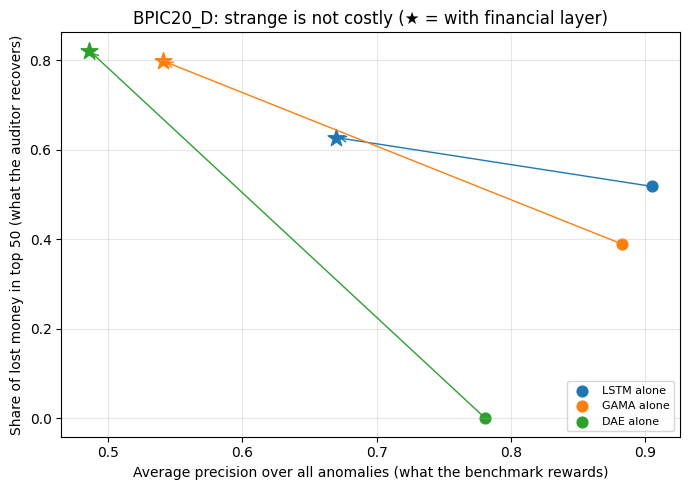

In [ ]:
# D.1 Strange is not costly: what the benchmark rewards vs what the auditor recovers (10:1)
SYS_ORDER = ([f"{d} {s}" for d in DETECTORS for s in ["alone", "× amount", "+ layer (rules v1)", "+ layer (rules v3)",
                                                         "+ layer (rules v3) + exploration"]]
             + ["amount alone", "rules v3 alone × money"])
r10 = R5[R5["ratio"] == max(RATIOS)]
cols = ["AP_any_anomaly", "PR_AUC_costly", f"LossRecall@{K}", f"EUR_loss_top{K}", f"decoys_in_top{K}",
        f"holdout_recall@{K}", "net_EUR_c25"]
head = r10.groupby("system")[cols].mean().reindex(SYS_ORDER).round(3)
print(f"{LOG_NAME} · TEST · decoys 10:1 · mean over seeds {SEEDS}")
print(head.to_string())
head.to_csv(f"{V5_DIR}/headline_ratio10.csv")

fig, ax = plt.subplots(figsize=(7, 5))
for det, c in zip(DETECTORS, ["tab:blue", "tab:orange", "tab:green"]):
    a = head.loc[f"{det} alone"]; b = head.loc[f"{det} + layer (rules v3)"]
    ax.scatter(a["AP_any_anomaly"], a[f"LossRecall@{K}"], color=c, s=60, label=f"{det} alone")
    ax.annotate("", xy=(b["AP_any_anomaly"], b[f"LossRecall@{K}"]), xytext=(a["AP_any_anomaly"], a[f"LossRecall@{K}"]),
                arrowprops=dict(arrowstyle="->", color=c))
    ax.scatter(b["AP_any_anomaly"], b[f"LossRecall@{K}"], color=c, marker="*", s=160)
ax.set_xlabel("Average precision over all anomalies (what the benchmark rewards)")
ax.set_ylabel(f"Share of lost money in top {K} (what the auditor recovers)")
ax.set_title(f"{LOG_NAME}: strange is not costly (★ = with financial layer)")
ax.grid(alpha=.3); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{V5_DIR}/strange_vs_costly.png", dpi=150); plt.show()


In [ ]:
# D.2 Improvement per detector and significance (10:1)
D5["result"] = D5.apply(lambda r: f"€{r.delta_EUR_loss_topK:+,.0f} [{r.CI95_low:+,.0f}, {r.CI95_high:+,.0f}]"
                        + (" *" if r.significant else ""), axis=1)
print("Δ lost money in top K, detector + layer (rules v3) vs ... (* = 95% interval excludes 0)")
print(D5.pivot_table(index=["detector", "comparison"], columns="seed", values="result", aggfunc="first").to_string())
WX = []
for comp, g_ in D5.groupby("comparison"):
    x = g_["delta_EUR_loss_topK"].values
    p = wilcoxon(x, alternative="greater").pvalue if (x != 0).any() and len(x) >= 5 else np.nan
    WX.append({"comparison": comp, "pairs": len(x), "improved": int((x > 0).sum()), "median_delta_EUR": np.median(x),
               "wilcoxon_p_one_sided": p})
WX = pd.DataFrame(WX); print("\nAcross detectors × seeds (this log):"); print(WX.round(4).to_string(index=False))
WX.to_csv(f"{V5_DIR}/wilcoxon_this_log.csv", index=False)


Δ lost money in top K, detector + layer (rules v3) vs ... (* = 95% interval excludes 0)
seed                                                                             404                         505                         606
detector comparison                                                                                                                         
DAE      + layer (rules v3) vs + layer (rules v1)           €+1,151 [+451, +1,930] *    €+1,318 [+444, +2,685] *    €+2,207 [+854, +3,964] *
         + layer (rules v3) vs alone                      €+3,055 [+1,579, +4,516] *  €+4,142 [+1,991, +7,420] *  €+3,207 [+1,607, +4,931] *
         + layer (rules v3) vs rules v3 alone × money                €-0 [-389, +67]           €-287 [-452, +24]             €-0 [-322, +43]
         + layer (rules v3) vs × amount                   €+2,146 [+1,187, +2,951] *  €+2,272 [+1,156, +3,592] *  €+2,788 [+1,427, +4,456] *
         + layer + exploration vs alone                   €+2,750 

In [ ]:
# D.3 Net benefit by review cost, and the effect of the decoy ratio
net = r10.groupby("system")[[f"net_EUR_c{c}" for c in REVIEW_COSTS]].mean().reindex(SYS_ORDER).round(0)
print("Net benefit at K=50 (lost money recovered − cost × 50), 10:1:"); print(net.to_string())
net.to_csv(f"{V5_DIR}/net_benefit.csv")
byr = R5.pivot_table(index="system", columns="ratio", values=f"LossRecall@{K}", aggfunc="mean").reindex(SYS_ORDER).round(3)
print(f"\nLoss Recall@{K} by decoys per costly anomaly:"); print(byr.to_string())
byr.to_csv(f"{V5_DIR}/loss_recall_by_ratio.csv")


Net benefit at K=50 (lost money recovered − cost × 50), 10:1:
                                       net_EUR_c10  net_EUR_c25  net_EUR_c50  net_EUR_c100
system                                                                                    
LSTM alone                                  1720.0        970.0       -280.0       -2780.0
LSTM × amount                                695.0        -55.0      -1305.0       -3805.0
LSTM + layer (rules v1)                     1778.0       1028.0       -222.0       -2722.0
LSTM + layer (rules v3)                     2192.0       1442.0        192.0       -2308.0
LSTM + layer (rules v3) + exploration       1975.0       1225.0        -25.0       -2525.0
GAMA alone                                  1200.0        450.0       -800.0       -3300.0
GAMA × amount                                934.0        184.0      -1066.0       -3566.0
GAMA + layer (rules v1)                     1422.0        672.0       -578.0       -3078.0
GAMA + layer (rules v3)     

In [ ]:
# D.4 Leave-one-type-out: does the detector help on a fraud type with no rule and no labels?
lt = L5.groupby(["held_out_type", "system"])[f"recall@{K}"].mean().unstack("system").round(3)
print(f"Recall@{K} of the held-out type (its rule removed, its labels withheld), mean over seeds:")
print(lt.to_string()); lt.to_csv(f"{V5_DIR}/leave_one_type_out_summary.csv")


Recall@50 of the held-out type (its rule removed, its labels withheld), mean over seeds:
system         DAE + layer  DAE + layer + exploration  DAE alone  GAMA + layer  GAMA + layer + exploration  GAMA alone  LSTM + layer  LSTM + layer + exploration  LSTM alone  rules alone
held_out_type                                                                                                                                                                            
A1                   0.000                      0.000        0.0         0.062                       0.062       0.083         0.188                       0.438       1.000        0.000
A5                   0.062                      0.062        0.0         0.083                       0.062       0.000         0.208                       0.167       0.271        0.062
C1                   0.000                      0.000        0.0         0.000                       0.000       0.000         0.000                       0.000       

In [ ]:
# D.5 Verdicts for this log
def mean_of(sys_, col):
    return r10[r10.system == sys_][col].mean()
V = []
for det in DETECTORS:
    a, b = f"{det} alone", f"{det} + layer (rules v3)"
    V.append({"detector": det,
              "H14 AP_any → Loss Recall (alone)": f"{mean_of(a, 'AP_any_anomaly'):.2f} → {mean_of(a, f'LossRecall@{K}'):.2f}",
              "H15 € lost money in top K: alone → + layer": f"€{mean_of(a, f'EUR_loss_top{K}'):,.0f} → €{mean_of(b, f'EUR_loss_top{K}'):,.0f}",
              "H16 vs rules alone / × amount": f"€{mean_of('rules v3 alone × money', f'EUR_loss_top{K}'):,.0f} / €{mean_of(f'{det} × amount', f'EUR_loss_top{K}'):,.0f}",
              "H18 net benefit better at every cost": all(net.loc[b].values > net.loc[a].values),
              "H19 hybrid: € lost money / held-out recall": f"€{mean_of(b + ' + exploration', f'EUR_loss_top{K}'):,.0f} / "
                  f"{L5[L5.system == det + ' + layer + exploration'][f'recall@{K}'].mean():.2f} vs layer "
                  f"{L5[L5.system == det + ' + layer'][f'recall@{K}'].mean():.2f}"})
V = pd.DataFrame(V); print(V.to_string(index=False)); V.to_csv(f"{V5_DIR}/verdicts.csv", index=False)
print("\nDONE for", LOG_NAME, "->", V5_DIR)


detector H14 AP_any → Loss Recall (alone) H15 € lost money in top K: alone → + layer H16 vs rules alone / × amount  H18 net benefit better at every cost H19 hybrid: € lost money / held-out recall
    LSTM                      0.91 → 0.52                            €2,220 → €2,692               €3,564 / €1,195                                  True                €2,475 / 0.25 vs layer 0.15
    GAMA                      0.88 → 0.39                            €1,700 → €3,386               €3,564 / €1,434                                  True                €3,194 / 0.18 vs layer 0.04
     DAE                      0.78 → 0.00                                €0 → €3,468               €3,564 / €1,066                                  True                €3,226 / 0.02 vs layer 0.02

DONE for BPIC20_D -> /content/drive/MyDrive/FCA_PAD_v2/19_v5_detectors


## Part E · Across logs (run after this notebook has run for each log)


In [ ]:
# E.1 Combine every log; Wilcoxon over detector × log × seed
allr, alld, alll = [], [], []
for lg in ["BPIC20_D", "BPIC20_I", "BPIC20_PR", "BPIC20_R"]:
    d_ = (BASE_ROOT if lg == "BPIC20_D" else f"{BASE_ROOT}/{lg}") + "/19_v5_detectors"
    if not os.path.exists(f"{d_}/metrics_by_seed_ratio.csv"):
        print(lg, "- not run yet"); continue
    for lst, f_ in [(allr, "metrics_by_seed_ratio.csv"), (alld, "deltas_ratio10.csv"), (alll, "leave_one_type_out.csv")]:
        x = pd.read_csv(f"{d_}/{f_}"); x.insert(0, "log", lg); lst.append(x)
if allr:
    sd = f"{BASE_ROOT}/19_v5_summary"; os.makedirs(sd, exist_ok=True)
    AR, AD, AL = (pd.concat(x, ignore_index=True) for x in (allr, alld, alll))
    AR.to_csv(f"{sd}/metrics_all_logs.csv", index=False); AD.to_csv(f"{sd}/deltas_all_logs.csv", index=False)
    AL.to_csv(f"{sd}/leave_one_type_out_all_logs.csv", index=False)
    a10 = AR[AR.ratio == max(RATIOS)]
    for metric in [f"LossRecall@{K}", f"decoys_in_top{K}", "net_EUR_c25", "AP_any_anomaly"]:
        pv = a10.pivot_table(index="system", columns="log", values=metric, aggfunc="mean").reindex(SYS_ORDER).round(3)
        print(f"\n{metric} (decoys 10:1, mean over seeds):"); print(pv.to_string())
        pv.to_csv(f"{sd}/{metric.replace('@', 'at')}_by_log.csv")
    W = []
    for comp, g_ in AD.groupby("comparison"):
        x = g_["delta_EUR_loss_topK"].values
        W.append({"comparison": comp, "pairs (detector×log×seed)": len(x), "improved": int((x > 0).sum()),
                  "significant_pairs": int(g_["significant"].sum()),
                  "wilcoxon_p_one_sided": wilcoxon(x, alternative="greater").pvalue if (x != 0).any() else np.nan})
    W = pd.DataFrame(W); print("\nOverall test (H15/H16):"); print(W.to_string(index=False))
    W.to_csv(f"{sd}/wilcoxon_all_logs.csv", index=False)
    print("\nLeave-one-type-out recall@K (all logs):")
    print(AL.groupby(["held_out_type", "system"])[f"recall@{K}"].mean().unstack("system").round(3).to_string())


BPIC20_I - not run yet
BPIC20_PR - not run yet
BPIC20_R - not run yet

LossRecall@50 (decoys 10:1, mean over seeds):
log                                    BPIC20_D
system                                         
LSTM alone                                0.518
LSTM × amount                             0.268
LSTM + layer (rules v1)                   0.527
LSTM + layer (rules v3)                   0.627
LSTM + layer (rules v3) + exploration     0.576
GAMA alone                                0.389
GAMA × amount                             0.323
GAMA + layer (rules v1)                   0.446
GAMA + layer (rules v3)                   0.798
GAMA + layer (rules v3) + exploration     0.755
DAE alone                                 0.000
DAE × amount                              0.242
DAE + layer (rules v1)                    0.443
DAE + layer (rules v3)                    0.821
DAE + layer (rules v3) + exploration      0.759
amount alone                              0.171
rules v3 alone × mo